# Tarea 3 — Kernels, SVC, árboles y evaluación

**Preguntas 1 a 4 integradas en una sola libreta.**

- **Pregunta 1:** kernel cuadrático $K(\mathbf{x},\mathbf{z})=(\mathbf{x}^\top\mathbf{z}+c)^2$ con $c=9$.
- **Preguntas 2, 3 y 4:** dataset *Rice Cammeo and Osmancik* (UCI, id 545), 3810 granos, 7 features morfológicas cuantitativas y una etiqueta binaria (`Cammeo` 42.8 %, `Osmancik` 57.2 %). Cumple los requisitos: entre 1000 y 10 000 ejemplos, entre 5 y 10 features y una etiqueta categórica.
- **Reproducibilidad:** `random_state=42` en la partición, en los modelos y en las búsquedas.
- **Partición única:** 80 % train / 20 % test, estratificada. Las preguntas 2, 3 y 4 usan exactamente la misma `X_train`, `X_test`, `y_train`, `y_test`.

> **Convención:** los valores entre corchetes `[...]` son los obtenidos con esta partición. Si cambias la semilla o el tamaño del test, reemplázalos por los que imprima tu ejecución.

In [1]:
%matplotlib inline

# ============================================================
# IMPORTACIONES GENERALES
# ============================================================
import itertools
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report, make_scorer,
)
from sklearn.dummy import DummyClassifier
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

FIG_DIR = Path("figs")
FIG_DIR.mkdir(exist_ok=True)

# Pregunta 1 — Kernel cuadrático (3 puntos)

Se estudia el kernel
$$
K(\mathbf{x},\mathbf{z}) = (\mathbf{x}^\top\mathbf{z}+c)^2 = \varphi(\mathbf{x})^\top\varphi(\mathbf{z}),
$$
con $c=9$ y $\mathbf{x},\mathbf{z}\in\mathbb{R}^2$. Se deduce $\varphi$, se calcula $\varphi([2,-3]^\top)$, se verifica la identidad con $\mathbf{z}=[1,4]^\top$, se generaliza a $d$ features y se compara el costo de calcular $\varphi(\mathbf{x})^\top\varphi(\mathbf{z})$ frente a $K(\mathbf{x},\mathbf{z})$.

## 1. Deducción de $\varphi$

Partimos de
$$
(\mathbf{x}^\top \mathbf{z} + c)^2
= \left(\sum_{i=1}^{d} x_i z_i + c\right)^2.
$$

Al desarrollar el cuadrado se obtienen cuatro tipos de términos:
$$
(\mathbf{x}^\top \mathbf{z} + c)^2
= \sum_{i=1}^{d} x_i^2 z_i^2
+ 2\sum_{1\le i<j\le d} x_i x_j z_i z_j
+ 2c\sum_{i=1}^{d} x_i z_i
+ c^2.
$$

Cada término se puede separar en un factor que depende de $\mathbf{x}$ y otro que depende de $\mathbf{z}$:

- $x_i^2 z_i^2 = (x_i^2)(z_i^2)$.
- $2x_i x_j z_i z_j = (\sqrt{2}\,x_i x_j)(\sqrt{2}\,z_i z_j)$.
- $2c\,x_i z_i = (\sqrt{2c}\,x_i)(\sqrt{2c}\,z_i)$.
- $c^2 = c\cdot c$.

Por lo tanto, una elección posible de $\varphi$ es
$$
\varphi(\mathbf{x}) =
\big[
\underbrace{x_1^2,\ldots,x_d^2}_{d\text{ cuadrados}},\;
\underbrace{\sqrt{2}\,x_i x_j\ (i<j)}_{d(d-1)/2\text{ cruzados}},\;
\underbrace{\sqrt{2c}\,x_1,\ldots,\sqrt{2c}\,x_d}_{d\text{ lineales}},\;
\underbrace{c}_{1\text{ constante}}
\big].
$$

Los pares $i<j$ se ordenan de forma lexicográfica: $(1,2),(1,3),\ldots,(d-1,d)$. Para $d=2$ queda
$$
\varphi(\mathbf{x}) =
[x_1^2,\; x_2^2,\; \sqrt{2}\,x_1x_2,\; \sqrt{2c}\,x_1,\; \sqrt{2c}\,x_2,\; c].
$$

> **Nota:** se necesita $c\ge 0$ para que $\sqrt{2c}$ sea real. En este punto $c=9$.

## 2. Implementación de $\varphi$ para cualquier dimensión

La función recibe un vector `x` y el valor `c`, y devuelve las componentes en el mismo orden de la deducción anterior. Se usa `itertools.combinations` para recorrer los pares $i<j$ sin repetirlos.

In [2]:
import itertools
import time

import numpy as np


def phi(x, c):
    """Devuelve φ(x) para el kernel K(x, z) = (x·z + c)²."""
    x = np.asarray(x, dtype=float)  # aseguramos un array de números reales
    d = x.size                      # dimensión del vector original

    # 1) Cuadrados: x₁², ..., x_d²
    cuadrados = x ** 2

    # 2) Términos cruzados: √2·x_i·x_j para cada par i < j.
    #    combinations(range(d), 2) genera (0,1), (0,2), ... en orden lexicográfico.
    cruzados = np.array(
        [np.sqrt(2.0) * x[i] * x[j] for i, j in itertools.combinations(range(d), 2)],
        dtype=float,
    )

    # 3) Términos lineales: √(2c)·x₁, ..., √(2c)·x_d
    lineales = np.sqrt(2.0 * c) * x

    # 4) Término constante: c
    constante = np.array([c], dtype=float)

    # El orden es siempre: cuadrados, cruzados, lineales, constante.
    return np.concatenate([cuadrados, cruzados, lineales, constante])

## 3. Punto a) — Cálculo de $\varphi([2,-3]^\top)$

Con $c=9$ y $\mathbf{x}=[2,-3]^\top$, calculamos el vector numérico usando la función anterior.

In [3]:
c = 9
x = np.array([2.0, -3.0])

phi_x = phi(x, c)

print("x =", x)
print("φ(x) =", np.round(phi_x, 4))
print()
print("Componentes de φ(x):")
print(f"  x₁²        = {phi_x[0]:.4f}")
print(f"  x₂²        = {phi_x[1]:.4f}")
print(f"  √2·x₁·x₂   = {phi_x[2]:.4f}")
print(f"  √(2c)·x₁   = {phi_x[3]:.4f}")
print(f"  √(2c)·x₂   = {phi_x[4]:.4f}")
print(f"  c          = {phi_x[5]:.4f}")

x = [ 2. -3.]
φ(x) = [  4.       9.      -8.4853   8.4853 -12.7279   9.    ]

Componentes de φ(x):
  x₁²        = 4.0000
  x₂²        = 9.0000
  √2·x₁·x₂   = -8.4853
  √(2c)·x₁   = 8.4853
  √(2c)·x₂   = -12.7279
  c          = 9.0000


**Forma exacta.** Como $\sqrt{2c}=\sqrt{18}=3\sqrt{2}$:

- $x_1^2 = 2^2 = 4$
- $x_2^2 = (-3)^2 = 9$
- $\sqrt{2}\,x_1x_2 = \sqrt{2}\cdot 2\cdot(-3) = -6\sqrt{2}$
- $\sqrt{2c}\,x_1 = 3\sqrt{2}\cdot 2 = 6\sqrt{2}$
- $\sqrt{2c}\,x_2 = 3\sqrt{2}\cdot(-3) = -9\sqrt{2}$
- $c = 9$

Por lo tanto,
$$
\varphi([2,-3]^\top) = [4,\; 9,\; -6\sqrt{2},\; 6\sqrt{2},\; -9\sqrt{2},\; 9]
\approx [4,\; 9,\; -8.4853,\; 8.4853,\; -12.7279,\; 9].
$$

## 4. Punto b) — Producto $\varphi(\mathbf{x})^\top\varphi(\mathbf{z})$ y kernel

Tomamos $\mathbf{z}=[1,4]^\top$ y comparamos el producto punto en el espacio de características con el valor directo del kernel.

In [4]:
z = np.array([1.0, 4.0])
phi_z = phi(z, c)

producto_phi = phi_x @ phi_z
producto_xz = x @ z
kernel = (producto_xz + c) ** 2

print("z =", z)
print("φ(z) =", np.round(phi_z, 4))
print()
print("φ(x)ᵀφ(z) =", round(float(producto_phi), 4))
print("xᵀz       =", round(float(producto_xz), 4))
print("K(x, z)   = (xᵀz + c)² =", round(float(kernel), 4))
print()
print("¿np.isclose(φ(x)ᵀφ(z), K(x, z))?", np.isclose(producto_phi, kernel))
if np.isclose(producto_phi, kernel):
    print("coinciden")

z = [1. 4.]
φ(z) = [ 1.     16.      5.6569  4.2426 16.9706  9.    ]

φ(x)ᵀφ(z) = 1.0
xᵀz       = -10.0
K(x, z)   = (xᵀz + c)² = 1.0

¿np.isclose(φ(x)ᵀφ(z), K(x, z))? True
coinciden


**Cálculo a mano de los 6 términos del producto punto.**

$$
\varphi(\mathbf{x}) \approx [4,\; 9,\; -8.4853,\; 8.4853,\; -12.7279,\; 9],
\qquad
\varphi(\mathbf{z}) \approx [1,\; 16,\; 5.6569,\; 4.2426,\; 16.9706,\; 9].
$$

Usando las formas exactas,
$$
\varphi(\mathbf{z}) = [1,\; 16,\; 4\sqrt{2},\; 3\sqrt{2},\; 12\sqrt{2},\; 9],
$$
y entonces
$$
\begin{aligned}
\varphi(\mathbf{x})^\top\varphi(\mathbf{z})
&= 4\cdot 1 + 9\cdot 16 + (-6\sqrt{2})(4\sqrt{2}) + (6\sqrt{2})(3\sqrt{2}) + (-9\sqrt{2})(12\sqrt{2}) + 9\cdot 9 \\
&= 4 + 144 - 48 + 36 - 216 + 81 \\
&= 1.
\end{aligned}
$$

Por otro lado, $\mathbf{x}^\top\mathbf{z} = 2\cdot 1 + (-3)\cdot 4 = 2-12 = -10$, así que
$$
K(\mathbf{x},\mathbf{z}) = (-10+9)^2 = (-1)^2 = 1.
$$

Por lo tanto, $\varphi(\mathbf{x})^\top\varphi(\mathbf{z}) = K(\mathbf{x},\mathbf{z}) = 1$: **coinciden**.

## 5. Verificación general para $d=3,5,10$

Para comprobar que la construcción de $\varphi$ no depende de $d=2$, repetimos la comparación con vectores aleatorios de dimensión $3$, $5$ y $10$. La semilla está fija para que el resultado sea reproducible.

In [5]:
rng = np.random.default_rng(0)  # semilla fija

print(f"{'d':>3} | {'φ(x)ᵀφ(z)':>14} | {'K(x,z)':>14} | {'np.allclose':>12}")
print("-" * 55)

for d in [3, 5, 10]:
    x_d = rng.normal(size=d)
    z_d = rng.normal(size=d)

    valor_phi = phi(x_d, c) @ phi(z_d, c)
    valor_kernel = (x_d @ z_d + c) ** 2
    coincide = np.allclose(valor_phi, valor_kernel)

    print(f"{d:>3} | {valor_phi:>14.4f} | {valor_kernel:>14.4f} | {str(coincide):>12}")
    assert coincide, f"Falla para d={d}"

print()
print("La construcción de φ funciona para cualquier dimensión probada.")

  d |      φ(x)ᵀφ(z) |         K(x,z) |  np.allclose
-------------------------------------------------------
  3 |        86.7790 |        86.7790 |         True
  5 |        81.7012 |        81.7012 |         True
 10 |       102.1041 |       102.1041 |         True

La construcción de φ funciona para cualquier dimensión probada.


## 6. Punto c) — Número de componentes de $\varphi$

Para un vector de dimensión $d$, $\varphi(\mathbf{x})$ tiene

$$
d \text{ cuadrados} + \frac{d(d-1)}{2} \text{ cruzados} + d \text{ lineales} + 1 \text{ constante}
= \frac{(d+1)(d+2)}{2}
$$

componentes. Por ejemplo: $d=2\Rightarrow 6$, $d=10\Rightarrow 66$, $d=100\Rightarrow 5151$ y $d=1000\Rightarrow 501501$. La tabla siguiente muestra también el desglose por tipo de término.

In [6]:
def n_componentes(d):
    """Cantidad de componentes de φ(x) para un vector de dimensión d."""
    return (d + 1) * (d + 2) // 2


# Verificación: la fórmula coincide con el largo real de φ(x) para d = 1..20.
rng = np.random.default_rng(0)
for d in range(1, 21):
    x_d = rng.normal(size=d)
    assert n_componentes(d) == len(phi(x_d, c)), f"Falla para d={d}"

print("Verificación OK: n_componentes(d) == len(phi(x, c)) para d = 1, ..., 20.")
print()

print(f"{'d':>6} | {'cuadrados':>10} | {'cruzados':>10} | {'lineales':>10} | {'constante':>10} | {'total':>10}")
print("-" * 72)

for d in [2, 10, 100, 1000]:
    cuadrados = d
    cruzados = d * (d - 1) // 2
    lineales = d
    constante = 1
    total = n_componentes(d)

    # La tabla también comprueba la descomposición del total.
    assert total == cuadrados + cruzados + lineales + constante
    print(f"{d:>6} | {cuadrados:>10} | {cruzados:>10} | {lineales:>10} | {constante:>10} | {total:>10}")

Verificación OK: n_componentes(d) == len(phi(x, c)) para d = 1, ..., 20.

     d |  cuadrados |   cruzados |   lineales |  constante |      total
------------------------------------------------------------------------
     2 |          2 |          1 |          2 |          1 |          6
    10 |         10 |         45 |         10 |          1 |         66
   100 |        100 |       4950 |        100 |          1 |       5151
  1000 |       1000 |     499500 |       1000 |          1 |     501501


## 7. Punto c) — Costo de calcular $\varphi(\mathbf{x})^\top\varphi(\mathbf{z})$ frente a $K(\mathbf{x},\mathbf{z})$

**Forma directa.** Hay que construir $\varphi(\mathbf{x})$ y $\varphi(\mathbf{z})$, cada uno con $N(d)=(d+1)(d+2)/2=\mathcal{O}(d^2)$ componentes, y luego multiplicarlos. El costo es $\mathcal{O}(d^2)$ en tiempo y también $\mathcal{O}(d^2)$ en memoria.

**Forma con el kernel.** Se calcula $\mathbf{x}^\top\mathbf{z}$ (producto punto de $d$ números), se suma $c$ y se eleva al cuadrado. El costo es $\mathcal{O}(d)$ en tiempo y $\mathcal{O}(1)$ de memoria adicional.

La medición siguiente es empírica y orientativa: incluye el costo de construir $\varphi$ en Python y depende de la máquina. Lo importante es la tendencia, no el valor exacto de cada tiempo. Para el método directo se usan más repeticiones cuando $d$ es chico y menos cuando $d$ es grande; para el kernel, que es muy barato, se usan muchas repeticiones siempre.

In [7]:
def producto_phi(x, z, c):
    """Forma directa: construir φ(x), φ(z) y hacer su producto punto."""
    return phi(x, c) @ phi(z, c)


def kernel_cuadratico(x, z, c):
    """Forma indirecta: evaluar K(x,z) sin construir φ."""
    return (x @ z + c) ** 2


def medir_tiempo(funcion, x, z, c, repeticiones):
    """Devuelve el tiempo promedio por llamada, en segundos."""
    # Una llamada de calentamiento para no medir la primera inicialización.
    funcion(x, z, c)

    inicio = time.perf_counter()
    for _ in range(repeticiones):
        funcion(x, z, c)
    fin = time.perf_counter()

    return (fin - inicio) / repeticiones


def repeticiones_directo(d):
    """Muchas repeticiones para d chico; menos para d grande."""
    n = n_componentes(d)
    return max(5, min(200, 3_000_000 // n))


# El kernel es muy barato (microsegundos), así que promediamos muchas llamadas.
REPS_KERNEL = 50_000

rng = np.random.default_rng(0)

print(f"{'d':>5} | {'N=len(φ)':>9} | {'reps φ':>7} | {'reps K':>7} | {'directo (s)':>13} | {'kernel (s)':>12} | {'cociente':>10}")
print("-" * 81)

for d in [10, 100, 500, 1000]:
    x_d = rng.normal(size=d)
    z_d = rng.normal(size=d)
    reps_directo = repeticiones_directo(d)

    t_directo = medir_tiempo(producto_phi, x_d, z_d, c, reps_directo)
    t_kernel = medir_tiempo(kernel_cuadratico, x_d, z_d, c, REPS_KERNEL)
    cociente = t_directo / t_kernel

    print(f"{d:>5} | {n_componentes(d):>9} | {reps_directo:>7} | {REPS_KERNEL:>7} | {t_directo:>13.3e} | {t_kernel:>12.3e} | {cociente:>10.1f}")

    d |  N=len(φ) |  reps φ |  reps K |   directo (s) |   kernel (s) |   cociente
---------------------------------------------------------------------------------
   10 |        66 |     200 |   50000 |     2.822e-05 |    6.403e-07 |       44.1


  100 |      5151 |     200 |   50000 |     2.076e-03 |    6.141e-07 |     3381.0


  500 |    125751 |      23 |   50000 |     1.071e-01 |    2.227e-06 |    48096.1


 1000 |    501501 |       5 |   50000 |     3.006e-01 |    2.303e-06 |   130533.4


**Lectura de la tabla.** El tiempo directo crece muy rápido con $d$: al pasar de $d=100$ a $d=1000$, el número de componentes se multiplica por casi $100$ y el tiempo directo también se acerca a ese factor. El tiempo del kernel se mantiene en el orden de los microsegundos: su costo teórico es $\mathcal{O}(d)$, pero para $d\le 1000$ pesa más el costo fijo de la llamada en Python que el producto punto. Por eso lo importante no es el valor exacto de cada tiempo, sino la tendencia: la brecha entre ambos métodos (la columna `cociente`) crece con $d$, y a $d=1000$ el método directo resulta cientos de miles de veces más lento en esta medición.

## 8. Conclusión

El kernel permite obtener el mismo número que se obtendría en un espacio de características grande, pero sin construir $\varphi(\mathbf{x})$ ni $\varphi(\mathbf{z})$. Eso ahorra tiempo y memoria: se pasa de $\mathcal{O}(d^2)$ a $\mathcal{O}(d)$. Por eso los SVM pueden trabajar con fronteras muy flexibles sin pagar el costo de la dimensión alta. El kernel gaussiano es el caso extremo: su $\varphi$ tiene infinitas componentes, así que no se puede construir; solo se puede usar evaluando $K(\mathbf{x},\mathbf{z})$. Esa es la idea central de los kernels: trabajar en dimensión alta (o infinita) a través de una función escalar.

# Pregunta 2 — SVC con kernel gaussiano (7 puntos)

## 2.1 Dataset y análisis exploratorio

El dataset **Rice Cammeo and Osmancik** contiene mediciones morfológicas de granos de arroz de dos variedades. Cada fila es un grano y las 7 features son cuantitativas:

| Feature | Qué mide |
|---|---|
| `Area` | Área del grano en la imagen. |
| `Perimeter` | Perímetro del contorno del grano. |
| `Major_Axis_Length` | Longitud del eje mayor de la elipse ajustada al grano. |
| `Minor_Axis_Length` | Longitud del eje menor de esa elipse. |
| `Eccentricity` | Excentricidad de la elipse: 0 sería un círculo y valores cercanos a 1 un grano muy alargado. |
| `Convex_Area` | Área del casco convexo del grano (envolvente convexa). |
| `Extent` | Razón entre el área del grano y el área de su caja envolvente; mide cuánto llena la caja. |

La etiqueta `Class` tiene dos clases: `Cammeo` y `Osmancik`. Se revisan faltantes, duplicados, tipos y proporciones de clase, y se visualiza la distribución de cada feature por clase.

Dimensiones: (3810, 8)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,Cammeo
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,Cammeo
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,Cammeo
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,Cammeo
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,Cammeo



Tipos de datos:


Area                 float64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Eccentricity         float64
Convex_Area          float64
Extent               float64
Class                    str
dtype: object

Valores faltantes: 0
Filas duplicadas: 0

Conteo por clase:


,conteo,proporción
Class,,
Osmancik,2180,0.5722
Cammeo,1630,0.4278



Estadísticos descriptivos:


,count,mean,std,min,25%,50%,75%,max
Area,3810.0,12667.728,1732.368,7551.000,11370.500,12421.500,13950.000,18913.000
Perimeter,3810.0,454.239,35.597,359.100,426.145,448.852,483.684,548.446
Major_Axis_Length,3810.0,188.776,17.449,145.264,174.354,185.810,203.550,239.010
Minor_Axis_Length,3810.0,86.314,5.730,59.532,82.732,86.435,90.144,107.542
Eccentricity,3810.0,0.887,0.021,0.777,0.872,0.889,0.903,0.948
Convex_Area,3810.0,12952.497,1776.972,7723.000,11626.250,12706.500,14284.000,19099.000
Extent,3810.0,0.662,0.077,0.497,0.599,0.645,0.727,0.861


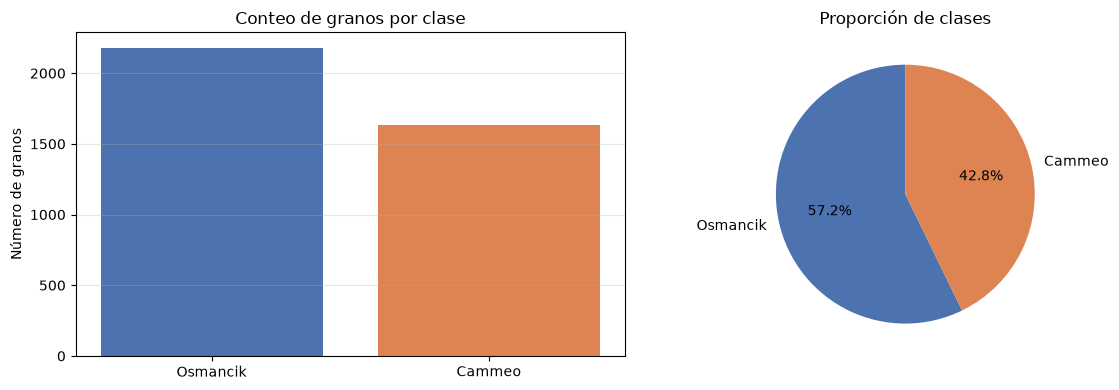

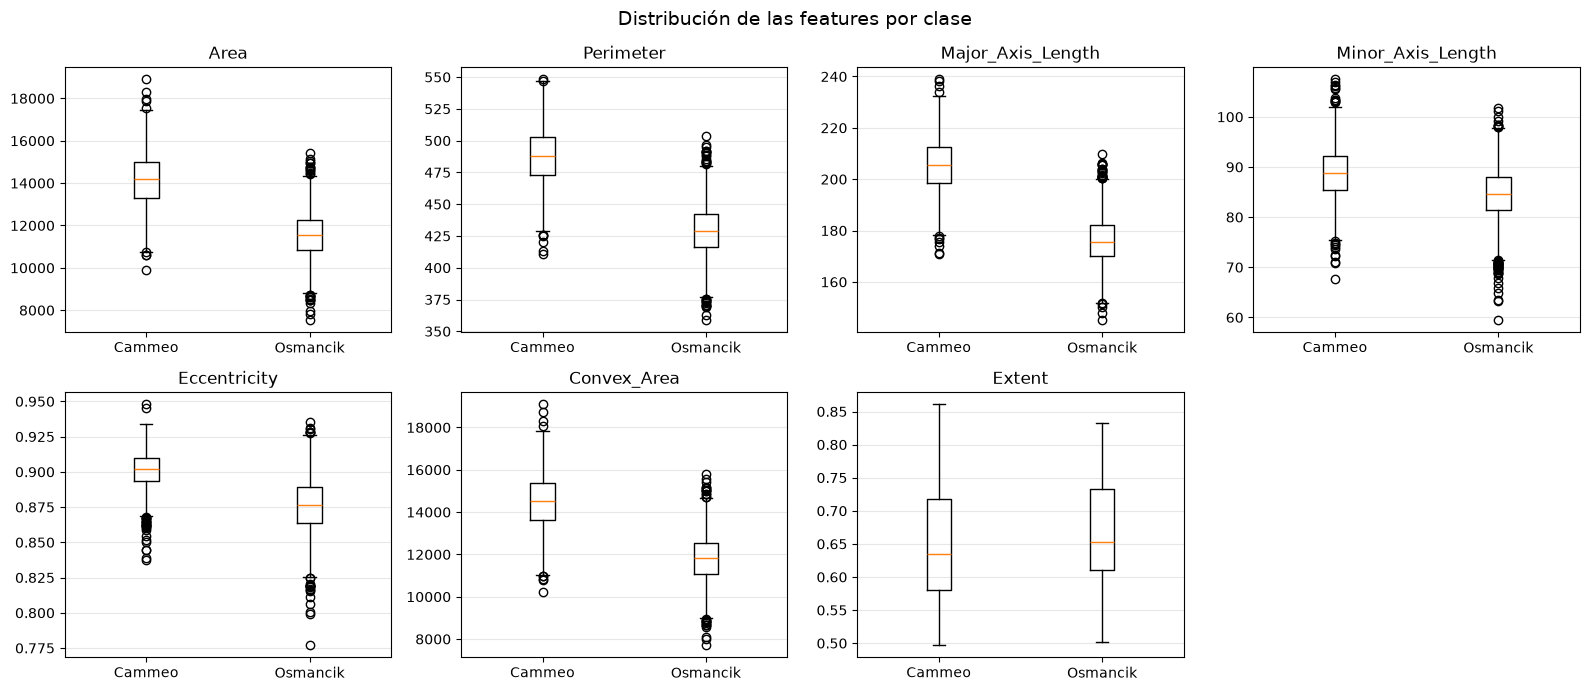


Partición:
X_train: (3048, 7) | X_test: (762, 7)
Distribución train: {'Cammeo': np.int64(1304), 'Osmancik': np.int64(1744)}
Distribución test : {'Cammeo': np.int64(326), 'Osmancik': np.int64(436)}


In [8]:
# ============================================================
# 2.1 Carga, revisión y EDA
# ============================================================
ruta_csv = Path("csv/rice.csv")
if not ruta_csv.exists():
    ruta_csv = Path("rice.csv")

df = pd.read_csv(ruta_csv)

print("Dimensiones:", df.shape)
display(df.head())
print("\nTipos de datos:")
display(df.dtypes)
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))

conteo = df["Class"].value_counts()
proporcion = df["Class"].value_counts(normalize=True)
print("\nConteo por clase:")
display(pd.DataFrame({"conteo": conteo, "proporción": proporcion}).round(4))
print("\nEstadísticos descriptivos:")
display(df.describe().T.round(3))

# Figura 1: balance de clases
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(conteo.index, conteo.values, color=["#4C72B0", "#DD8452"])
axes[0].set_title("Conteo de granos por clase")
axes[0].set_ylabel("Número de granos")
axes[0].grid(axis="y", alpha=0.3)
axes[1].pie(
    conteo.values, labels=conteo.index, autopct="%1.1f%%",
    colors=["#4C72B0", "#DD8452"], startangle=90,
)
axes[1].set_title("Proporción de clases")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_balance_clases.png", dpi=160, bbox_inches="tight")
plt.show()

# Figura 2: distribución de cada feature por clase
feature_names = [c for c in df.columns if c != "Class"]
class_names = sorted(df["Class"].unique())
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), feature_names):
    datos = [df.loc[df["Class"] == c, col].to_numpy() for c in class_names]
    ax.boxplot(datos, tick_labels=class_names)
    ax.set_title(col)
    ax.grid(axis="y", alpha=0.3)
for ax in axes.ravel()[len(feature_names):]:
    ax.axis("off")
fig.suptitle("Distribución de las features por clase", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_boxplots_features.png", dpi=160, bbox_inches="tight")
plt.show()

# Codificación de etiquetas y partición única para 2, 3 y 4
le = LabelEncoder()
y = le.fit_transform(df["Class"])
class_names = list(le.classes_)
X = df[feature_names].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("\nPartición:")
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Distribución train:", dict(zip(class_names, np.bincount(y_train))))
print("Distribución test :", dict(zip(class_names, np.bincount(y_test))))

**Lectura del EDA.** No hay valores faltantes ni filas duplicadas, y todas las features son numéricas; por eso no hace falta imputar ni eliminar registros. El desbalance es leve: `Osmancik` 57.2 % y `Cammeo` 42.8 %, razón aproximada 1.34 : 1. Los boxplots muestran que `Cammeo` tiende a tener mayor `Area`, `Perimeter`, `Major_Axis_Length`, `Minor_Axis_Length` y `Convex_Area`; `Eccentricity` y `Extent` se solapan más. Las escalas son muy distintas (`Area` ~ 10⁴ frente a `Extent` ~ 0.66), así que el SVC necesita estandarización. Para el análisis bidimensional se eligen `Major_Axis_Length` y `Perimeter`: son interpretables (largo y contorno del grano) y separan bien las clases.

## 2.2 SVC con dos features: efecto de `gamma` y `C`

Se usan solo `Major_Axis_Length` y `Perimeter`, estandarizadas con un `StandardScaler` ajustado en un subconjunto de entrenamiento. El train completo se divide en 80 % sub-train / 20 % validación para reportar exactitud de entrenamiento y de validación sin tocar el test. Se entrenan 6 modelos: 3 valores de `gamma` con `C=1` fijo y 3 valores de `C` con `gamma=0.1` fijo. En cada gráfico se marcan los vectores de soporte con círculos negros.

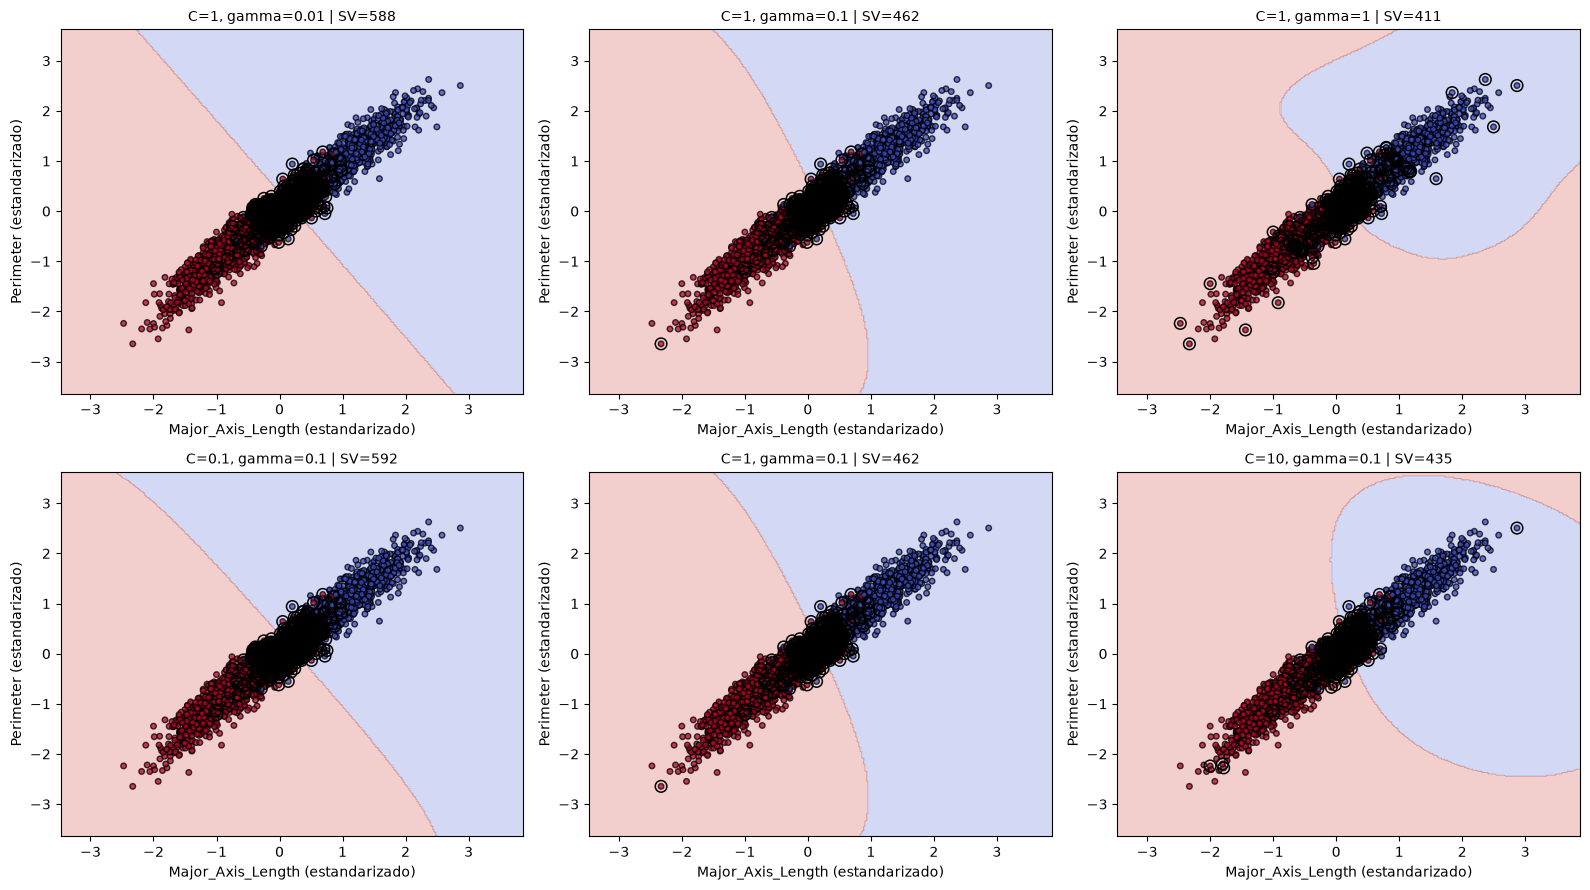

,Barrido,C,gamma,N° vectores de soporte,SV Cammeo,SV Osmancik,Exactitud train,Exactitud validación
0,gamma,1.0,0.01,588,294,294,0.9303,0.9328
1,gamma,1.0,0.10,462,231,231,0.9319,0.9344
2,gamma,1.0,1.00,411,206,205,0.9331,0.9344
3,C,0.1,0.10,592,296,296,0.9315,0.9328
4,C,1.0,0.10,462,231,231,0.9319,0.9344
5,C,10.0,0.10,435,217,218,0.9327,0.9361


In [9]:
# ============================================================
# 2.2 SVC bidimensional: gamma y C
# ============================================================
idx_2d = [feature_names.index("Major_Axis_Length"), feature_names.index("Perimeter")]
X_2d = X_train[:, idx_2d]

X_tr2, X_val2, y_tr2, y_val2 = train_test_split(
    X_2d, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)
scaler_2d = StandardScaler().fit(X_tr2)
X_tr2 = scaler_2d.transform(X_tr2)
X_val2 = scaler_2d.transform(X_val2)

def graficar_frontera(ax, modelo, X, y, titulo):
    DecisionBoundaryDisplay.from_estimator(
        modelo, X, response_method="predict", cmap="coolwarm",
        alpha=0.25, ax=ax, grid_resolution=300,
    )
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=16, alpha=0.75)
    ax.scatter(
        X[modelo.support_, 0], X[modelo.support_, 1],
        s=70, facecolors="none", edgecolors="black", linewidths=1.1,
        label="Vectores de soporte",
    )
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("Major_Axis_Length (estandarizado)")
    ax.set_ylabel("Perimeter (estandarizado)")

configuraciones = []
for gamma in [0.01, 0.1, 1]:
    configuraciones.append(("gamma", 1, gamma))
for C in [0.1, 1, 10]:
    configuraciones.append(("C", C, 0.1))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
filas_2d = []

for ax, (barrido, C, gamma) in zip(axes.ravel(), configuraciones):
    modelo = SVC(kernel="rbf", C=C, gamma=gamma, random_state=RANDOM_STATE)
    modelo.fit(X_tr2, y_tr2)
    acc_train = accuracy_score(y_tr2, modelo.predict(X_tr2))
    acc_val = accuracy_score(y_val2, modelo.predict(X_val2))
    nsv = len(modelo.support_)
    graficar_frontera(ax, modelo, X_tr2, y_tr2, f"C={C}, gamma={gamma} | SV={nsv}")
    filas_2d.append({
        "Barrido": barrido,
        "C": C,
        "gamma": gamma,
        "N° vectores de soporte": nsv,
        f"SV {class_names[0]}": modelo.n_support_[0],
        f"SV {class_names[1]}": modelo.n_support_[1],
        "Exactitud train": acc_train,
        "Exactitud validación": acc_val,
    })

fig.tight_layout()
fig.savefig(FIG_DIR / "02_svc_fronteras_gamma_C.png", dpi=160, bbox_inches="tight")
plt.show()

tabla_2d = pd.DataFrame(filas_2d)
display(tabla_2d.round(4))

**Cómo cambia la frontera.**
- **`gamma`** controla el ancho del kernel RBF. Con `gamma=0.01` la frontera es muy suave y casi global: el modelo es más rígido, usa más vectores de soporte (`[588]`) y la exactitud de validación es `[0.9328]`. Al subir a `gamma=0.1` la frontera se curva para adaptarse a la forma local de cada clase, baja el número de vectores de soporte a `[462]` y la validación sube a `[0.9344]`. Con `gamma=1` la frontera es aún más local, usa `[411]` vectores y la validación se mantiene en `[0.9344]`, mientras el train sube levemente a `[0.9331]`. En este problema `gamma` alto no llega a sobreajustar de forma grave porque las clases están bien separadas, pero en general un `gamma` excesivo produce fronteras muy irregulares y mala generalización.
- **`C`** controla la penalización de los errores y, por tanto, el margen. Con `C=0.1` el margen es ancho y blando: hay más vectores de soporte (`[592]`) y la validación es `[0.9328]`. Con `C=1` baja a `[462]` vectores y la validación sube a `[0.9344]`. Con `C=10` el margen es más estrecho, el modelo se ajusta más al train, usa `[435]` vectores y la validación llega a `[0.9361]`. Un `C` muy alto puede sobreajustar; aquí la mejora es pequeña, señal de que el problema es relativamente fácil en estas dos features.
- **Vectores de soporte:** son los puntos que están sobre el margen o dentro de él. Al aumentar `C` o `gamma`, el modelo se vuelve más “duro” y suele necesitar menos vectores, porque tolera menos errores y ajusta la frontera más cerca de los puntos difíciles.

La exactitud en 2D (≈ `[0.93]` de validación) es cercana a la del modelo con las 7 features, lo que confirma que `Major_Axis_Length` y `Perimeter` concentran gran parte de la señal.

## 2.3 Pipeline `StandardScaler + SVC` y búsqueda de `C` y `gamma`

Se construye un `Pipeline` para que el escalado se ajuste dentro de cada pliegue de validación cruzada y no haya fuga de información. La rejilla usa valores en escala logarítmica: `C ∈ {0.1, 1, 10, 100}` y `gamma ∈ {0.001, 0.01, 0.1, 1}`. Se evalúa con 5 pliegues y exactitud. El score de prueba del mejor modelo se reporta **una sola vez**, al final de esta sección.

Mejores hiperparámetros: {'svc__C': 10, 'svc__gamma': 0.01}
Exactitud media de validación cruzada: 0.9324
Tiempo de GridSearchCV: 5.22 s

Score del mejor SVC sobre el conjunto de prueba (se reporta una sola vez): 0.9160


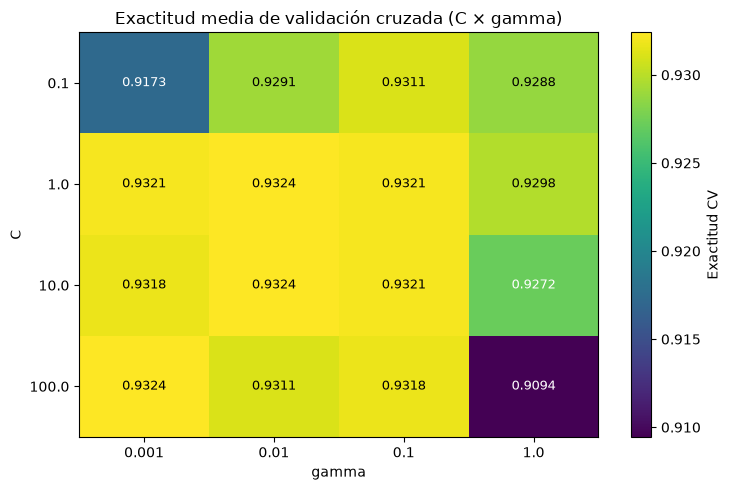

param_svc__gamma,0.001,0.010,0.100,1.000
param_svc__C,,,,
0.1,0.9173,0.9291,0.9311,0.9288
1.0,0.9321,0.9324,0.9321,0.9298
10.0,0.9318,0.9324,0.9321,0.9272
100.0,0.9324,0.9311,0.9318,0.9094


In [10]:
# ============================================================
# 2.3 Pipeline + GridSearchCV + mapa de calor
# ============================================================
pipe_svc = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", random_state=RANDOM_STATE)),
])

svc_param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.001, 0.01, 0.1, 1],
}

t0 = time.perf_counter()
svc_search = GridSearchCV(
    pipe_svc, svc_param_grid, cv=5, scoring="accuracy",
    n_jobs=-1, return_train_score=True,
)
svc_search.fit(X_train, y_train)
tiempo_svc_search = time.perf_counter() - t0
svc_best = svc_search.best_estimator_

print("Mejores hiperparámetros:", svc_search.best_params_)
print(f"Exactitud media de validación cruzada: {svc_search.best_score_:.4f}")
print(f"Tiempo de GridSearchCV: {tiempo_svc_search:.2f} s")

score_test_svc = svc_best.score(X_test, y_test)
print(f"\nScore del mejor SVC sobre el conjunto de prueba (se reporta una sola vez): {score_test_svc:.4f}")

# Mapa de calor C x gamma
res_cv = pd.DataFrame(svc_search.cv_results_)
tabla_cv = res_cv.pivot(
    index="param_svc__C", columns="param_svc__gamma", values="mean_test_score"
)

fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(tabla_cv.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(tabla_cv.columns)))
ax.set_xticklabels([str(g) for g in tabla_cv.columns])
ax.set_yticks(range(len(tabla_cv.index)))
ax.set_yticklabels([str(c) for c in tabla_cv.index])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("Exactitud media de validación cruzada (C × gamma)")
for i in range(tabla_cv.shape[0]):
    for j in range(tabla_cv.shape[1]):
        valor = tabla_cv.values[i, j]
        color = "white" if valor < tabla_cv.values.max() - 0.005 else "black"
        ax.text(j, i, f"{valor:.4f}", ha="center", va="center", color=color, fontsize=9)
fig.colorbar(im, ax=ax, label="Exactitud CV")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_heatmap_C_gamma.png", dpi=160, bbox_inches="tight")
plt.show()

display(tabla_cv.round(4))

**Lectura del mapa de calor.** La mejor combinación es `C = [10]`, `gamma = [0.01]`, con exactitud media de validación `[0.9324]` y score de prueba `[0.9160]`. La zona de buen rendimiento es amplia: `gamma` entre `[0.01]` y `[0.1]` y `C` entre `[1]` y `[100]` dan valores cercanos a `[0.93]`. Con `gamma=0.001` el modelo es demasiado suave y la exactitud baja; con `gamma=1` la frontera se vuelve muy local y la validación no mejora. El mejor modelo es un pipeline, así que internamente estandariza las 7 features antes del SVC; esto evita que `Area` o `Convex_Area` dominen la distancia por su escala. El score de prueba `[0.9160]` es la referencia del SVC para las preguntas 3 y 4.

# Pregunta 3 — Árbol de decisión y Random Forest (6 puntos)

Se usa exactamente la misma `X_train`, `X_test`, `y_train`, `y_test` de la pregunta 2. Los árboles no necesitan escalado, así que se entrenan con las features en su escala original; esto hace que los umbrales del árbol sean directamente interpretables en las unidades de `Major_Axis_Length`, `Perimeter`, etc.

## 3.1 Elección de `max_depth` con GridSearchCV

Se busca `max_depth` entre 1 y 20 con validación cruzada de 5 pliegues. Se guarda también la exactitud de entrenamiento para diagnosticar sobreajuste.

Mejor max_depth: 4
Exactitud de validación cruzada: 0.9298
Exactitud de prueba: 0.9121
Tiempo de GridSearchCV: 0.44 s


,max_depth,Exactitud CV,Desv. est. CV,Exactitud train
0,1,0.9288,0.0157,0.9322
1,2,0.9288,0.0157,0.9322
2,3,0.9239,0.0138,0.9332
3,4,0.9298,0.0126,0.9374
4,5,0.9252,0.0148,0.9427
5,6,0.9213,0.0101,0.9493
6,7,0.9157,0.0056,0.9564
7,8,0.9117,0.0055,0.9637
8,9,0.9114,0.0069,0.9707
9,10,0.9042,0.0095,0.9772


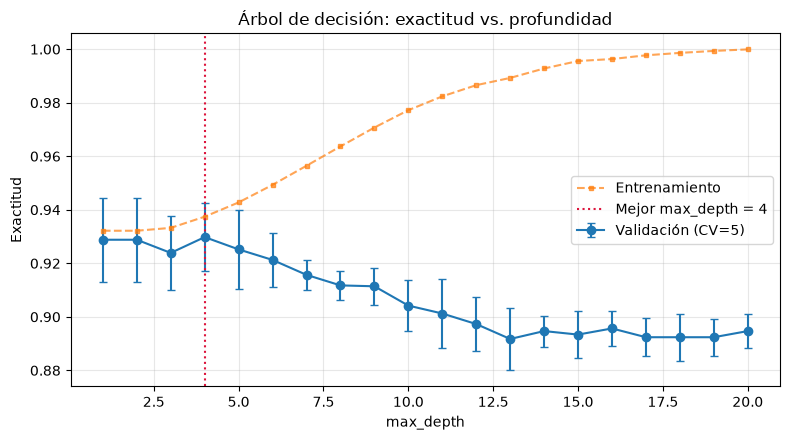

In [11]:
# ============================================================
# 3.1 GridSearchCV para max_depth del árbol
# ============================================================
tree_param_grid = {"max_depth": list(range(1, 21))}

t0 = time.perf_counter()
tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    tree_param_grid, cv=5, scoring="accuracy",
    n_jobs=-1, return_train_score=True,
)
tree_search.fit(X_train, y_train)
tiempo_tree_search = time.perf_counter() - t0
tree_best = tree_search.best_estimator_

print("Mejor max_depth:", tree_search.best_params_["max_depth"])
print(f"Exactitud de validación cruzada: {tree_search.best_score_:.4f}")
print(f"Exactitud de prueba: {tree_best.score(X_test, y_test):.4f}")
print(f"Tiempo de GridSearchCV: {tiempo_tree_search:.2f} s")

resultados_tree = pd.DataFrame({
    "max_depth": tree_param_grid["max_depth"],
    "Exactitud CV": tree_search.cv_results_["mean_test_score"],
    "Desv. est. CV": tree_search.cv_results_["std_test_score"],
    "Exactitud train": tree_search.cv_results_["mean_train_score"],
})
display(resultados_tree.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(
    resultados_tree["max_depth"], resultados_tree["Exactitud CV"],
    yerr=resultados_tree["Desv. est. CV"], marker="o", capsize=3,
    label="Validación (CV=5)",
)
ax.plot(
    resultados_tree["max_depth"], resultados_tree["Exactitud train"],
    marker="s", markersize=3, linestyle="--", alpha=0.7,
    label="Entrenamiento",
)
ax.axvline(
    tree_search.best_params_["max_depth"], color="crimson", linestyle=":",
    label=f"Mejor max_depth = {tree_search.best_params_['max_depth']}",
)
ax.set_xlabel("max_depth")
ax.set_ylabel("Exactitud")
ax.set_title("Árbol de decisión: exactitud vs. profundidad")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03a_tree_depth.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretación.** El mejor valor es `max_depth = [4]`, con exactitud de validación `[0.9298]` y de entrenamiento `[0.9374]`. Hasta profundidad 4 el árbol gana detalle sin sobreajustar; desde 5 la validación baja (`[0.9252]` en 5, `[0.8947]` en 20) mientras el train sube hasta casi 1. Eso es sobreajuste. Las profundidades 1 y 2 empatan en `[0.9288]`, lo que sugiere que la señal principal está en pocas variables y cortes.

## 3.2 Árbol de profundidad 3 y lectura del proceso de decisión

Se entrena un árbol aparte con `max_depth=3` para dibujarlo y leerlo. No es necesariamente el árbol con mejor CV; es el árbol de interpretación. Se muestran el gráfico, las reglas en texto y una tabla con `gini`, `samples`, `value` y clase predicha de cada nodo.

Exactitud train del árbol de profundidad 3: 0.9334
Exactitud test  del árbol de profundidad 3: 0.9160
Número de hojas: 8 | Profundidad: 3


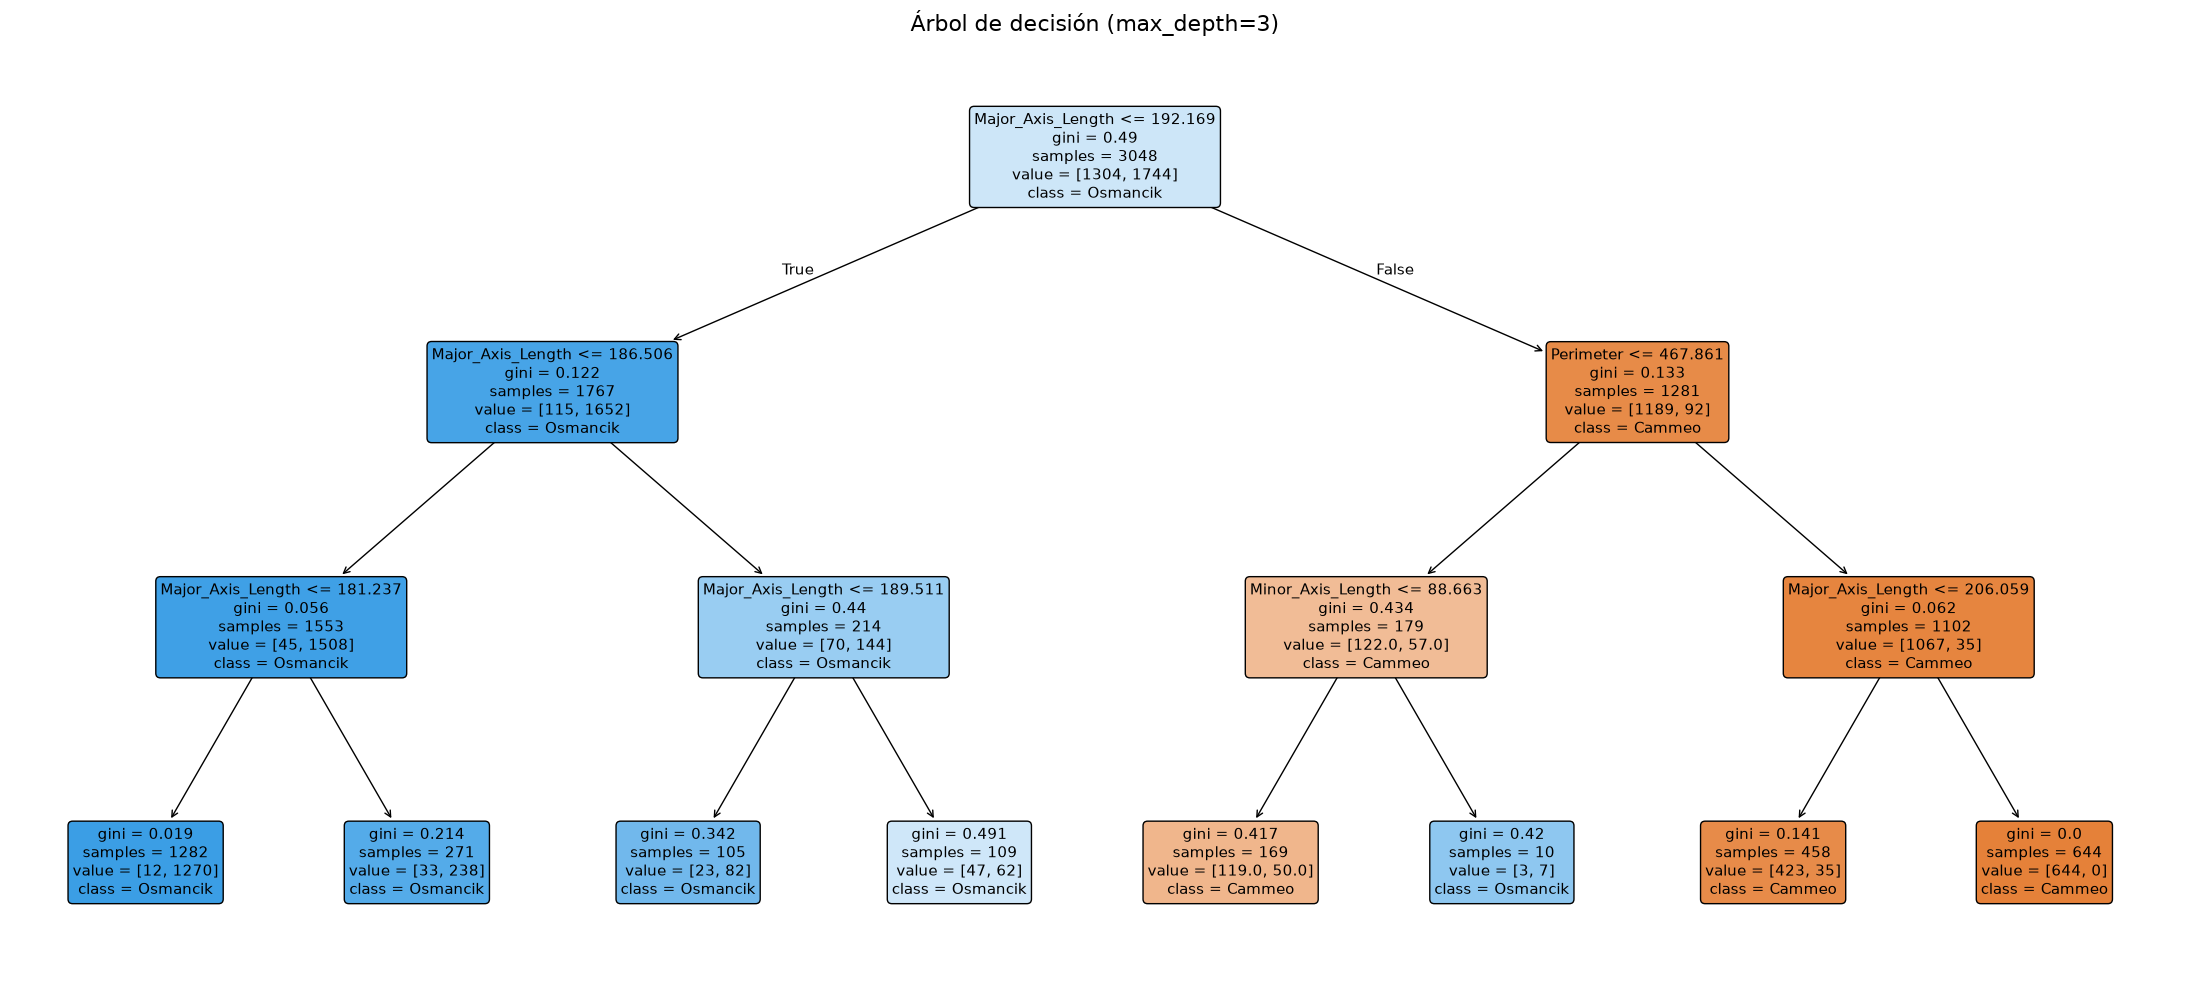


Reglas del árbol (thresholds en unidades originales):
|--- Major_Axis_Length <= 192.169
|   |--- Major_Axis_Length <= 186.506
|   |   |--- Major_Axis_Length <= 181.237
|   |   |   |--- class: Osmancik
|   |   |--- Major_Axis_Length >  181.237
|   |   |   |--- class: Osmancik
|   |--- Major_Axis_Length >  186.506
|   |   |--- Major_Axis_Length <= 189.511
|   |   |   |--- class: Osmancik
|   |   |--- Major_Axis_Length >  189.511
|   |   |   |--- class: Osmancik
|--- Major_Axis_Length >  192.169
|   |--- Perimeter <= 467.861
|   |   |--- Minor_Axis_Length <= 88.663
|   |   |   |--- class: Cammeo
|   |   |--- Minor_Axis_Length >  88.663
|   |   |   |--- class: Osmancik
|   |--- Perimeter >  467.861
|   |   |--- Major_Axis_Length <= 206.059
|   |   |   |--- class: Cammeo
|   |   |--- Major_Axis_Length >  206.059
|   |   |   |--- class: Cammeo



,Nodo,Condición,gini,samples,value_Cammeo,value_Osmancik,Clase predicha
0,0,Major_Axis_Length <= 192.169,0.4896,3048,0.4278,0.5722,Osmancik
1,1,Major_Axis_Length <= 186.506,0.1217,1767,0.0651,0.9349,Osmancik
2,2,Major_Axis_Length <= 181.237,0.0563,1553,0.0290,0.9710,Osmancik
3,3,hoja,0.0185,1282,0.0094,0.9906,Osmancik
4,4,hoja,0.2139,271,0.1218,0.8782,Osmancik
5,5,Major_Axis_Length <= 189.511,0.4402,214,0.3271,0.6729,Osmancik
6,6,hoja,0.3421,105,0.2190,0.7810,Osmancik
7,7,hoja,0.4905,109,0.4312,0.5688,Osmancik
8,8,Perimeter <= 467.861,0.1333,1281,0.9282,0.0718,Cammeo
9,9,Minor_Axis_Length <= 88.663,0.4341,179,0.6816,0.3184,Cammeo


In [12]:
# ============================================================
# 3.2 Árbol de profundidad 3
# ============================================================
tree3 = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree3.fit(X_train, y_train)

print(f"Exactitud train del árbol de profundidad 3: {tree3.score(X_train, y_train):.4f}")
print(f"Exactitud test  del árbol de profundidad 3: {tree3.score(X_test, y_test):.4f}")
print(f"Número de hojas: {tree3.get_n_leaves()} | Profundidad: {tree3.get_depth()}")

fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    tree3, feature_names=feature_names, class_names=class_names,
    filled=True, rounded=True, fontsize=11, precision=3, ax=ax,
)
ax.set_title("Árbol de decisión (max_depth=3)", fontsize=16)
fig.tight_layout()
fig.savefig(FIG_DIR / "03b_tree3.png", dpi=160, bbox_inches="tight")
plt.show()

print("\nReglas del árbol (thresholds en unidades originales):")
print(export_text(tree3, feature_names=feature_names, class_names=class_names, decimals=3))

filas_nodos = []
for i in range(tree3.tree_.node_count):
    f = tree3.tree_.feature[i]
    valores = tree3.tree_.value[i].ravel()
    fila = {
        "Nodo": i,
        "Condición": (
            f"{feature_names[f]} <= {tree3.tree_.threshold[i]:.3f}"
            if f >= 0 else "hoja"
        ),
        "gini": tree3.tree_.impurity[i],
        "samples": tree3.tree_.n_node_samples[i],
    }
    for j, c in enumerate(class_names):
        fila[f"value_{c}"] = valores[j]
    fila["Clase predicha"] = class_names[int(np.argmax(valores))]
    filas_nodos.append(fila)

tabla_nodos = pd.DataFrame(filas_nodos)
display(tabla_nodos.round(4))

### Lectura del árbol de profundidad 3

Los umbrales están en las unidades originales de las features.

**Raíz (nodo 0).** La primera condición es `Major_Axis_Length <= [192.169]`. El nodo tiene `gini = [0.4896]`, `samples = [3048]` y `value = [1304 Cammeo, 1744 Osmancik]`; es decir, 42.78 % Cammeo y 57.22 % Osmancik. Como la mayoría es Osmancik, la clase predicha en la raíz es **Osmancik**. El `gini` es cercano al máximo de una binaria (0.5), así que la raíz parte una población todavía muy mezclada. La condición separa granos con eje mayor corto (rama izquierda) de granos con eje mayor largo (rama derecha).

**Rama izquierda: granos con eje mayor corto.** El nodo 1 vuelve a cortar por `Major_Axis_Length <= [186.506]`. Tiene `gini = [0.1217]`, `samples = [1767]` y `value = [115, 1652]`: 93.49 % Osmancik. Es un nodo mucho más puro que la raíz. El nodo 2 corta por `Major_Axis_Length <= [181.237]` y llega a `gini = [0.0563]`, `samples = [1553]`, `value = [45, 1508]` (97.10 % Osmancik). Sus dos hojas (nodos 3 y 4) predicen **Osmancik**. El nodo 5, para los granos que quedan entre 186.506 y 192.169, corta por `Major_Axis_Length <= [189.511]` y tiene `gini = [0.4402]`, `samples = [214]`, `value = [70, 144]` (67.29 % Osmancik); sus hojas 6 y 7 también predicen **Osmancik**. En consecuencia, **toda la rama izquierda termina en Osmancik**. La hoja 7 es un ejemplo de hoja impura: `gini = [0.4905]`, `samples = [109]`, `value = [47, 62]` (56.88 % Osmancik); aun así predice Osmancik porque es la clase mayoritaria y el árbol ya alcanzó la profundidad máxima.

**Rama derecha: granos con eje mayor largo.** El nodo 8 corta por `Perimeter <= [467.861]`. Tiene `gini = [0.1333]`, `samples = [1281]` y `value = [1189, 92]`: 92.82 % Cammeo; predice **Cammeo**. El nodo 9, para los granos con perímetro pequeño, corta por `Minor_Axis_Length <= [88.663]` y tiene `gini = [0.4341]`, `samples = [179]`, `value = [122, 57]` (68.16 % Cammeo). La hoja 10 (169 granos, `value = [119, 50]`, 70.41 % Cammeo) predice **Cammeo**; la hoja 11 es la excepción: solo 10 granos, `value = [3, 7]` (70 % Osmancik), `gini = [0.4200]`, y predice **Osmancik**. Es una hoja de soporte muy bajo, así que su efecto es pequeño y conviene no interpretarla como una regla general. El nodo 12, para los granos con perímetro grande, corta por `Major_Axis_Length <= [206.059]` y tiene `gini = [0.0615]`, `samples = [1102]`, `value = [1067, 35]` (96.82 % Cammeo). La hoja 13 (458 granos, `value = [423, 35]`, 92.36 % Cammeo) predice Cammeo; la hoja 14 es pura: `gini = [0.0000]`, `samples = [644]`, `value = [644, 0]`, 100 % Cammeo.

**Síntesis del proceso.** El árbol primero usa el largo del eje mayor para aislar un bloque grande de granos cortos, que resultan ser casi todos Osmancik. Para los granos largos, usa el perímetro y el eje menor para separar Cammeo; dentro de los granos largos y de perímetro grande, un último corte por eje mayor deja un grupo completamente Cammeo. La regla global se puede resumir así: **si el grano es corto (`Major_Axis_Length <= [192.169]`), se predice Osmancik; si es largo, se predice Cammeo, salvo el pequeño grupo de 10 granos con perímetro pequeño y eje menor grande, que se clasifica como Osmancik**. Esto es coherente con el dominio: Cammeo tiende a granos más grandes (mayor área, perímetro y eje mayor) que Osmancik.

**Qué significan `gini`, `samples` y `value`.**
- `gini` mide la impureza del nodo: 0 = nodo puro (una sola clase), 0.5 = máxima mezcla en un problema binario. La raíz (`[0.4896]`) está cerca de la máxima mezcla; la hoja 14 (`[0.0000]`) es pura.
- `samples` es el número de granos de entrenamiento que llegan a ese nodo. La raíz recibe los `[3048]` granos del train; la hoja 11 recibe solo `[10]`.
- `value` es el conteo de cada clase en el nodo (no la proporción). Por ejemplo, en el nodo 1, `value = [115, 1652]` significa 115 Cammeo y 1652 Osmancik; en la hoja 14, `value = [644, 0]` significa 644 Cammeo y 0 Osmancik. La clase predicha es la del mayor conteo.

En este split, el árbol de profundidad 3 obtiene `[0.9160]` en test, incluso por encima del árbol óptimo por CV (`[0.9121]`); es una diferencia dentro del ruido, pero muestra que la profundidad 4 no es necesariamente mejor en test.

## 3.3 Random Forest con GridSearchCV

Se buscan `n_estimators`, `max_depth` y `max_features` con 5 pliegues. `max_features=None` significa que cada corte considera las 7 features; `'sqrt'` considera ≈√7 y `'log2'` ≈ log₂ 7. Se usa `n_jobs=1` dentro del bosque y `n_jobs=-1` en el `GridSearchCV` para no anidar paralelismo.

Mejores hiperparámetros: {'max_depth': 5, 'max_features': None, 'n_estimators': 100}
Exactitud de validación cruzada: 0.9301
Exactitud de prueba: 0.9121
Tiempo de GridSearchCV: 20.42 s


,n_estimators,max_depth,max_features,Exactitud CV,Desv. est. CV,Exactitud train,Ranking
15,100,5,NaN,0.9301,0.0134,0.9435,1
11,300,5,sqrt,0.9295,0.0133,0.9436,2
14,300,5,log2,0.9295,0.0133,0.9436,2
9,100,5,sqrt,0.9291,0.0128,0.9436,4
12,100,5,log2,0.9291,0.0128,0.9436,4
10,200,5,sqrt,0.9288,0.0132,0.9432,6
13,200,5,log2,0.9288,0.0132,0.9432,6
16,200,5,NaN,0.9288,0.0132,0.9446,6
17,300,5,NaN,0.9288,0.0124,0.9444,6
19,200,10,sqrt,0.9275,0.0121,0.9877,10


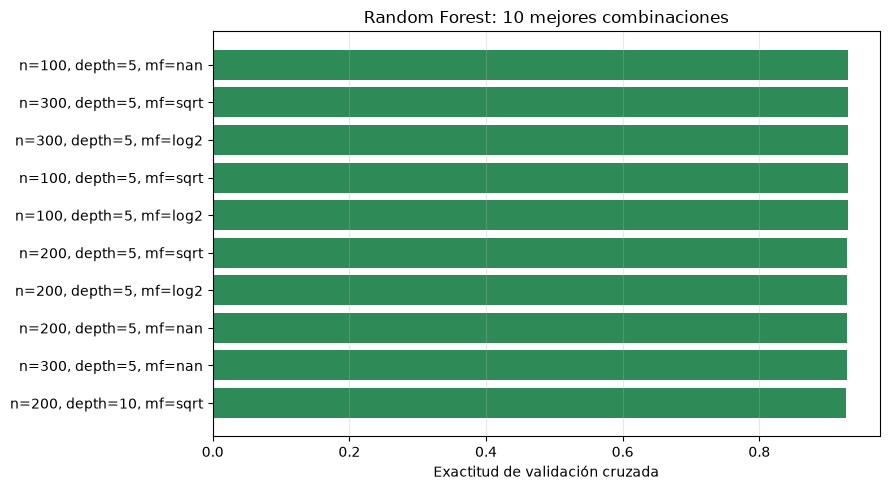

In [13]:
# ============================================================
# 3.3 GridSearchCV para RandomForestClassifier
# ============================================================
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 20],
    "max_features": ["sqrt", "log2", None],
}

t0 = time.perf_counter()
rf_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    rf_param_grid, cv=5, scoring="accuracy",
    n_jobs=-1, return_train_score=True,
)
rf_search.fit(X_train, y_train)
tiempo_rf_search = time.perf_counter() - t0
rf_best = rf_search.best_estimator_

print("Mejores hiperparámetros:", rf_search.best_params_)
print(f"Exactitud de validación cruzada: {rf_search.best_score_:.4f}")
print(f"Exactitud de prueba: {rf_best.score(X_test, y_test):.4f}")
print(f"Tiempo de GridSearchCV: {tiempo_rf_search:.2f} s")

resultados_rf = pd.DataFrame(rf_search.cv_results_).copy()
resultados_rf["max_features_etiqueta"] = resultados_rf["param_max_features"].astype(str)
columnas = [
    "param_n_estimators", "param_max_depth", "max_features_etiqueta",
    "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score",
]
tabla_rf = resultados_rf.sort_values("rank_test_score")[columnas].head(12)
tabla_rf.columns = [
    "n_estimators", "max_depth", "max_features",
    "Exactitud CV", "Desv. est. CV", "Exactitud train", "Ranking",
]
display(tabla_rf.round(4))

top10 = resultados_rf.sort_values("rank_test_score").head(10).iloc[::-1]
etiquetas = [
    f"n={int(f['param_n_estimators'])}, depth={f['param_max_depth']}, mf={f['max_features_etiqueta']}"
    for _, f in top10.iterrows()
]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(etiquetas, top10["mean_test_score"], color="seagreen")
ax.set_xlabel("Exactitud de validación cruzada")
ax.set_title("Random Forest: 10 mejores combinaciones")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "03c_rf_top10.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretación.** La mejor combinación es `n_estimators = [100]`, `max_depth = [5]`, `max_features = [None]`, con exactitud de validación `[0.9301]` y de entrenamiento `[0.9435]`. Las combinaciones con `max_depth=5` ocupan casi todo el top 10; las de `max_depth=10` o `None` tienen mayor exactitud de entrenamiento (`[0.9877]` o más) pero menor validación, señal de sobreajuste. Pasar de 100 a 200 o 300 árboles no mejora de forma apreciable: el bosque ya está estabilizado. Con solo 7 features, `max_features=None` es razonable; `'sqrt'` y `'log2'` quedan muy cerca (`[0.9295]`).

## 3.4 Exactitud de prueba del árbol y del Random Forest

Se comparan los tres modelos con la misma partición. Se incluye la exactitud de entrenamiento, la de prueba, el mejor score de validación y un tiempo de ajuste medido con un solo `fit`.

In [14]:
# ============================================================
# 3.4 Tabla comparativa de exactitud
# ============================================================
modelos = {"SVC": svc_best, "Árbol": tree_best, "Random Forest": rf_best}
svc_estimator = svc_best.named_steps["svc"]

resumen_params = {
    "SVC": f"C={svc_estimator.C}, gamma={svc_estimator.gamma}, kernel={svc_estimator.kernel}",
    "Árbol": f"max_depth={tree_best.max_depth}",
    "Random Forest": (
        f"n_estimators={rf_best.n_estimators}, "
        f"max_depth={rf_best.max_depth}, max_features={rf_best.max_features}"
    ),
}
cv_scores = {
    "SVC": svc_search.best_score_,
    "Árbol": tree_search.best_score_,
    "Random Forest": rf_search.best_score_,
}
tiempos_grid = {
    "SVC": tiempo_svc_search,
    "Árbol": tiempo_tree_search,
    "Random Forest": tiempo_rf_search,
}

filas = []
for nombre, modelo in modelos.items():
    t0 = time.perf_counter()
    clone(modelo).fit(X_train, y_train)
    tiempo_fit = time.perf_counter() - t0
    filas.append({
        "Modelo": nombre,
        "Hiperparámetros": resumen_params[nombre],
        "Exactitud CV": cv_scores[nombre],
        "Exactitud train": modelo.score(X_train, y_train),
        "Exactitud test": modelo.score(X_test, y_test),
        "Tiempo GridSearchCV (s)": tiempos_grid[nombre],
        "Tiempo de un fit (s)": tiempo_fit,
    })

tabla_3d = pd.DataFrame(filas)
display(tabla_3d.round(4))

,Modelo,Hiperparámetros,Exactitud CV,Exactitud train,Exactitud test,Tiempo GridSearchCV (s),Tiempo de un fit (s)
0,SVC,"C=10, gamma=0.01, kernel=rbf",0.9324,0.9327,0.9160,5.2247,0.0370
1,Árbol,max_depth=4,0.9298,0.9380,0.9121,0.4359,0.0065
2,Random Forest,"n_estimators=100, max_depth=5, max_features=None",0.9301,0.9423,0.9121,20.4217,0.4705


**Interpretación.** Las exactitudes de prueba son muy parecidas: SVC `[0.9160]`, árbol `[0.9121]` y Random Forest `[0.9121]`. La diferencia entre el mejor y los otros dos es de `[0.0039]` (0.39 puntos porcentuales), menor que la desviación estándar típica de la validación cruzada (`[0.0126]`–`[0.0134]`), así que **no se puede afirmar que haya una diferencia significativa** con este test de 762 granos. El SVC gana por un margen mínimo; el árbol es el más rápido y el más interpretable; el Random Forest queda en un punto intermedio. Los scores de validación (`[0.9324]`, `[0.9298]`, `[0.9301]`) son algo mayores que los de prueba, lo cual es normal.

# Pregunta 4 — Evaluación y comparación (4 puntos)

## 4.1 Matrices de confusión y métricas por clase

Se calculan las matrices de confusión de los tres modelos sobre `X_test` en una sola figura con tres subgráficas. Después se muestra el `classification_report` y una tabla con precisión y sensibilidad (recall) por clase. En las matrices, las filas son la clase real y las columnas la clase predicha; el orden es `Cammeo`, `Osmancik`.

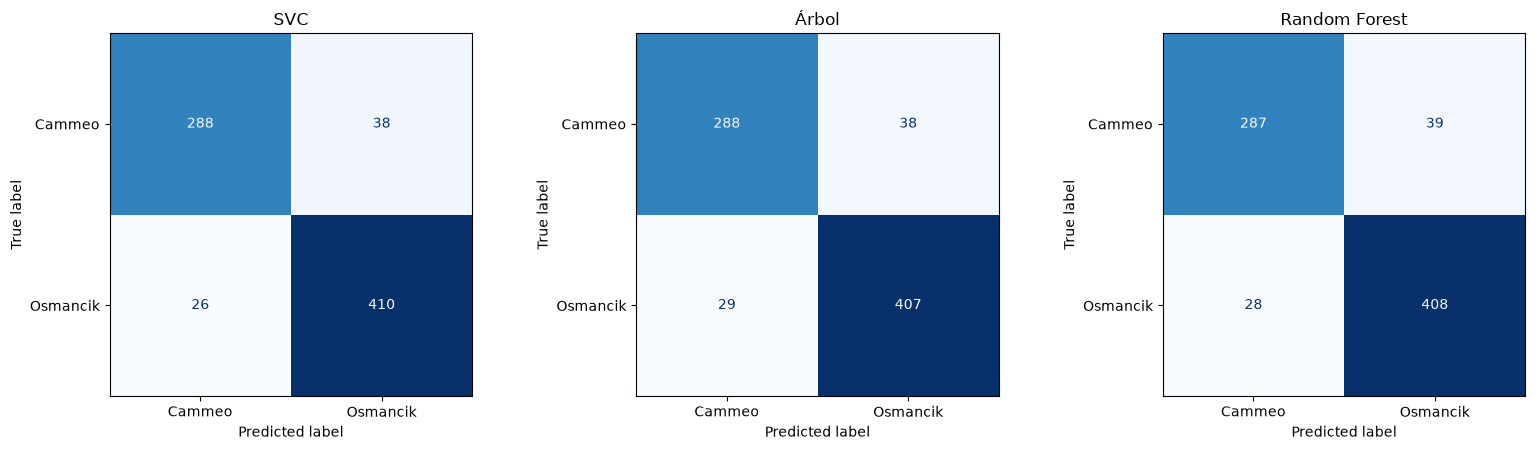


=== SVC ===
              precision    recall  f1-score   support

      Cammeo     0.9172    0.8834    0.9000       326
    Osmancik     0.9152    0.9404    0.9276       436

    accuracy                         0.9160       762
   macro avg     0.9162    0.9119    0.9138       762
weighted avg     0.9160    0.9160    0.9158       762


=== Árbol ===
              precision    recall  f1-score   support

      Cammeo     0.9085    0.8834    0.8958       326
    Osmancik     0.9146    0.9335    0.9240       436

    accuracy                         0.9121       762
   macro avg     0.9116    0.9085    0.9099       762
weighted avg     0.9120    0.9121    0.9119       762


=== Random Forest ===
              precision    recall  f1-score   support

      Cammeo     0.9111    0.8804    0.8955       326
    Osmancik     0.9128    0.9358    0.9241       436

    accuracy                         0.9121       762
   macro avg     0.9119    0.9081    0.9098       762
weighted avg     0.9120

,Modelo,Exactitud,Balanced accuracy,F1 macro,Precisión Cammeo,Recall Cammeo,F1 Cammeo,Precisión Osmancik,Recall Osmancik,F1 Osmancik
0,SVC,0.9160,0.9119,0.9138,0.9172,0.8834,0.9000,0.9152,0.9404,0.9276
1,Árbol,0.9121,0.9085,0.9099,0.9085,0.8834,0.8958,0.9146,0.9335,0.9240
2,Random Forest,0.9121,0.9081,0.9098,0.9111,0.8804,0.8955,0.9128,0.9358,0.9241


In [15]:
# ============================================================
# 4.1 Matrices de confusión y métricas por clase
# ============================================================
predicciones = {nombre: modelo.predict(X_test) for nombre, modelo in modelos.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (nombre, y_pred) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=class_names,
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(nombre)
fig.tight_layout()
fig.savefig(FIG_DIR / "04a_confusion_3modelos.png", dpi=160, bbox_inches="tight")
plt.show()

for nombre, y_pred in predicciones.items():
    print(f"\n=== {nombre} ===")
    print(classification_report(
        y_test, y_pred, labels=range(len(class_names)),
        target_names=class_names, digits=4,
    ))

filas = []
for nombre, y_pred in predicciones.items():
    precision = precision_score(y_test, y_pred, average=None, labels=range(len(class_names)))
    recall = recall_score(y_test, y_pred, average=None, labels=range(len(class_names)))
    f1 = f1_score(y_test, y_pred, average=None, labels=range(len(class_names)))
    fila = {
        "Modelo": nombre,
        "Exactitud": accuracy_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
    }
    for i, c in enumerate(class_names):
        fila[f"Precisión {c}"] = precision[i]
        fila[f"Recall {c}"] = recall[i]
        fila[f"F1 {c}"] = f1[i]
    filas.append(fila)

tabla_4a = pd.DataFrame(filas)
display(tabla_4a.round(4))

**Interpretación de las matrices.** Con 326 Cammeo y 436 Osmancik en el test:
- SVC: `[288]` Cammeo bien clasificados y `[38]` Cammeo predichos como Osmancik; `[26]` Osmancik predichos como Cammeo y `[410]` Osmancik bien clasificados. Total: `[64]` errores.
- Árbol: `[288/38]` en Cammeo y `[29/407]` en Osmancik; `[67]` errores.
- Random Forest: `[287/39]` en Cammeo y `[28/408]` en Osmancik; `[67]` errores.

Los tres modelos cometen más errores con **Cammeo** (38–39 falsos Osmancik, 11.7–12.0 % de los Cammeo) que con Osmancik (26–29 falsos Cammeo, 6.0–6.7 %). Eso se refleja en el recall: Cammeo `[0.880–0.883]` frente a Osmancik `[0.934–0.940]`. La precisión es más equilibrada: Cammeo `[0.908–0.917]`, Osmancik `[0.913–0.915]`. En este test, el SVC es el mejor en las tres métricas globales (`[0.9160]` de exactitud, `[0.9119]` de balanced accuracy, `[0.9138]` de F1 macro), pero la ventaja sobre el árbol y el bosque es pequeña.

## 4.2 ¿Es óptimo usar la exactitud por defecto en GridSearchCV?

La exactitud es el promedio ponderado por el número de muestras de cada clase. Con desbalance, una clase mayoritaria puede dominar el score: un modelo que ignore la minoría puede tener exactitud alta y, aun así, ser inútil para esa clase. Además, la exactitud trata todos los errores como iguales, aunque en muchas aplicaciones el costo de un falso negativo y un falso positivo no es el mismo.

En este dataset el desbalance es **leve** (57.2 % Osmancik vs. 42.8 % Cammeo), así que la exactitud no está tan sesgada como en un caso 90/10. Pero sí oculta la brecha de recall entre clases. La línea base trivial (predecir siempre Osmancik) da exactitud `[0.5722]`, balanced accuracy `[0.5000]` y F1 macro `[0.3639]`; nuestros modelos están muy por encima, luego la exactitud no es engañosa en el sentido extremo, pero sigue siendo una métrica parcial.

Se repite la búsqueda con `scoring='f1_macro'` y `scoring='balanced_accuracy'` para los tres modelos, usando las mismas rejillas. También se muestra el caso de `scoring='recall'`: en binario, por defecto optimiza el recall de la etiqueta positiva (`Osmancik=1`), no el de la minoría; para optimizar Cammeo hay que usar `make_scorer(recall_score, pos_label=0)`.

In [16]:
# ============================================================
# 4.2 Comparación de métricas de búsqueda
# ============================================================
def comparar_scoring(nombre, estimador, param_grid, busqueda_accuracy):
    '''Entrena la misma rejilla con accuracy, f1_macro y balanced_accuracy.'''
    filas = []
    for scoring in ["accuracy", "f1_macro", "balanced_accuracy"]:
        if scoring == "accuracy" and busqueda_accuracy is not None:
            busqueda = busqueda_accuracy
        else:
            busqueda = GridSearchCV(
                clone(estimador), param_grid, cv=5, scoring=scoring, n_jobs=-1
            )
            busqueda.fit(X_train, y_train)

        y_pred = busqueda.predict(X_test)
        recall_clases = recall_score(
            y_test, y_pred, average=None, labels=range(len(class_names))
        )
        filas.append({
            "Modelo": nombre,
            "scoring": scoring,
            "Mejores hiperparámetros": str(busqueda.best_params_),
            "Score CV": busqueda.best_score_,
            "Exactitud test": accuracy_score(y_test, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
            "F1 macro": f1_score(y_test, y_pred, average="macro"),
            f"Recall {class_names[0]}": recall_clases[0],
            f"Recall {class_names[1]}": recall_clases[1],
        })
    return pd.DataFrame(filas)

comparaciones = [
    comparar_scoring(
        "SVC",
        Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf", random_state=RANDOM_STATE))]),
        svc_param_grid,
        svc_search,
    ),
    comparar_scoring(
        "Árbol",
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        tree_param_grid,
        tree_search,
    ),
    comparar_scoring(
        "Random Forest",
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        rf_param_grid,
        rf_search,
    ),
]

tabla_4b = pd.concat(comparaciones, ignore_index=True)
display(tabla_4b.round(4))

# Caso especial: recall de la clase positiva (Osmancik) vs. recall de Cammeo
escenarios_recall = {
    "recall (positivo = Osmancik)": "recall",
    "recall Cammeo (pos_label=0)": make_scorer(recall_score, pos_label=0),
}
filas_recall = []
for nombre, scoring in escenarios_recall.items():
    busqueda = GridSearchCV(
        Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf", random_state=RANDOM_STATE))]),
        svc_param_grid, cv=5, scoring=scoring, n_jobs=-1,
    )
    busqueda.fit(X_train, y_train)
    y_pred = busqueda.predict(X_test)
    recalls = recall_score(y_test, y_pred, average=None, labels=range(len(class_names)))
    filas_recall.append({
        "Criterio": nombre,
        "Mejores hiperparámetros": str(busqueda.best_params_),
        "Score CV": busqueda.best_score_,
        "Exactitud test": accuracy_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        f"Recall {class_names[0]}": recalls[0],
        f"Recall {class_names[1]}": recalls[1],
    })

display(pd.DataFrame(filas_recall).round(4))

,Modelo,scoring,Mejores hiperparámetros,Score CV,Exactitud test,Balanced accuracy,F1 macro,Recall Cammeo,Recall Osmancik
0,SVC,accuracy,"{'svc__C': 10, 'svc__gamma': 0.01}",0.9324,0.9160,0.9119,0.9138,0.8834,0.9404
1,SVC,f1_macro,"{'svc__C': 1, 'svc__gamma': 0.01}",0.9310,0.9160,0.9123,0.9139,0.8865,0.9381
2,SVC,balanced_accuracy,"{'svc__C': 1, 'svc__gamma': 0.01}",0.9313,0.9160,0.9123,0.9139,0.8865,0.9381
3,Árbol,accuracy,{'max_depth': 4},0.9298,0.9121,0.9085,0.9099,0.8834,0.9335
4,Árbol,f1_macro,{'max_depth': 4},0.9281,0.9121,0.9085,0.9099,0.8834,0.9335
5,Árbol,balanced_accuracy,{'max_depth': 1},0.9278,0.9160,0.9115,0.9137,0.8804,0.9427
6,Random Forest,accuracy,"{'max_depth': 5, 'max_features': None, 'n_esti...",0.9301,0.9121,0.9081,0.9098,0.8804,0.9358
7,Random Forest,f1_macro,"{'max_depth': 5, 'max_features': None, 'n_esti...",0.9285,0.9121,0.9081,0.9098,0.8804,0.9358
8,Random Forest,balanced_accuracy,"{'max_depth': 5, 'max_features': None, 'n_esti...",0.9281,0.9121,0.9081,0.9098,0.8804,0.9358


,Criterio,Mejores hiperparámetros,Score CV,Exactitud test,Balanced accuracy,Recall Cammeo,Recall Osmancik
0,recall (positivo = Osmancik),"{'svc__C': 0.1, 'svc__gamma': 0.001}",0.9622,0.9016,0.8919,0.8252,0.9587
1,recall Cammeo (pos_label=0),"{'svc__C': 1, 'svc__gamma': 0.01}",0.9233,0.9160,0.9123,0.8865,0.9381


**Interpretación de la tabla.** Los resultados concretos son:
- **SVC:** con `accuracy` gana `C=10, gamma=0.01`; con `f1_macro` o `balanced_accuracy` gana `C=1, gamma=0.01`. La exactitud de prueba no cambia (`[0.9160]`), pero el modelo con `C=1` tiene balanced accuracy `[0.9123]` frente a `[0.9119]` y recall de Cammeo `[0.8865]` frente a `[0.8834]`. La búsqueda por exactitud elige un modelo un poco más complejo; la diferencia práctica es mínima.
- **Árbol:** con `accuracy` y `f1_macro` gana `max_depth=4`; con `balanced_accuracy` gana `max_depth=1`. El árbol de profundidad 1 es mucho más simple y obtiene exactitud de prueba `[0.9160]`, balanced accuracy `[0.9115]` y F1 macro `[0.9137]`, frente a `[0.9121]`, `[0.9085]` y `[0.9099]` del árbol de profundidad 4. En este test, el modelo más simple incluso generaliza mejor; el recall de Cammeo baja levemente (`[0.8804]` vs. `[0.8834]`), pero el de Osmancik sube (`[0.9427]` vs. `[0.9335]`).
- **Random Forest:** las tres métricas eligen la misma combinación (`n_estimators=100`, `max_depth=5`, `max_features=None`). Cambia el score de validación (`[0.9301]`, `[0.9285]`, `[0.9281]`), pero no los hiperparámetros ni las métricas de prueba. En este caso, usar exactitud no fue perjudicial.
- **Recall:** `scoring='recall'` elige `C=0.1, gamma=0.001` y optimiza el recall de Osmancik (`[0.9587]`), pero baja el de Cammeo a `[0.8252]` y la exactitud a `[0.9016]`. Para optimizar Cammeo hay que usar `make_scorer(recall_score, pos_label=0)`, que elige `C=1, gamma=0.01` y da recall de Cammeo `[0.8865]` con exactitud `[0.9160]`.

**Conclusión de 4.2.** Para este dataset, la exactitud no es una mala elección porque el desbalance es leve y los modelos superan ampliamente la línea base; pero **no es la métrica más alineada con el objetivo si se quiere tratar igual a las dos clases**. `F1 macro` y `balanced_accuracy` son más informativas y, en el árbol, llevan a un modelo más simple. Si el costo de no detectar un Cammeo es alto, lo correcto es optimizar el recall de Cammeo con `make_scorer(..., pos_label=0)` o usar `class_weight='balanced'` (parte 4.4). Si el costo de ambos errores es similar, `f1_macro` o `balanced_accuracy` son una elección defendible. En el informe conviene reportar exactitud **y** métricas macro, no solo una.

## 4.3 SVC vs. Random Forest e importancia de features

### Importancia de features del Random Forest

Se muestran dos medidas: la importancia por impureza (Gini) que calcula el bosque sobre el train y la importancia por permutación calculada sobre el test. La primera es rápida pero está sesgada hacia variables continuas con muchos valores distintos y se calcula con los datos de entrenamiento; la segunda mide cuánto empeora la exactitud al permutar cada variable en el test y es más representativa de la generalización. Con variables correlacionadas, la permutación puede repartir la importancia entre ellas y subestimar alguna.

,Feature,Importancia por impureza (Gini),Importancia por permutación (media),Desv. est. permutación
2,Major_Axis_Length,0.9377,0.3112,0.0142
1,Perimeter,0.0315,0.1657,0.0079
6,Extent,0.0103,-0.0009,0.0022
0,Area,0.0060,0.0015,0.0015
3,Minor_Axis_Length,0.0052,-0.0009,0.0013
4,Eccentricity,0.0049,0.0001,0.0010
5,Convex_Area,0.0045,-0.0025,0.0017


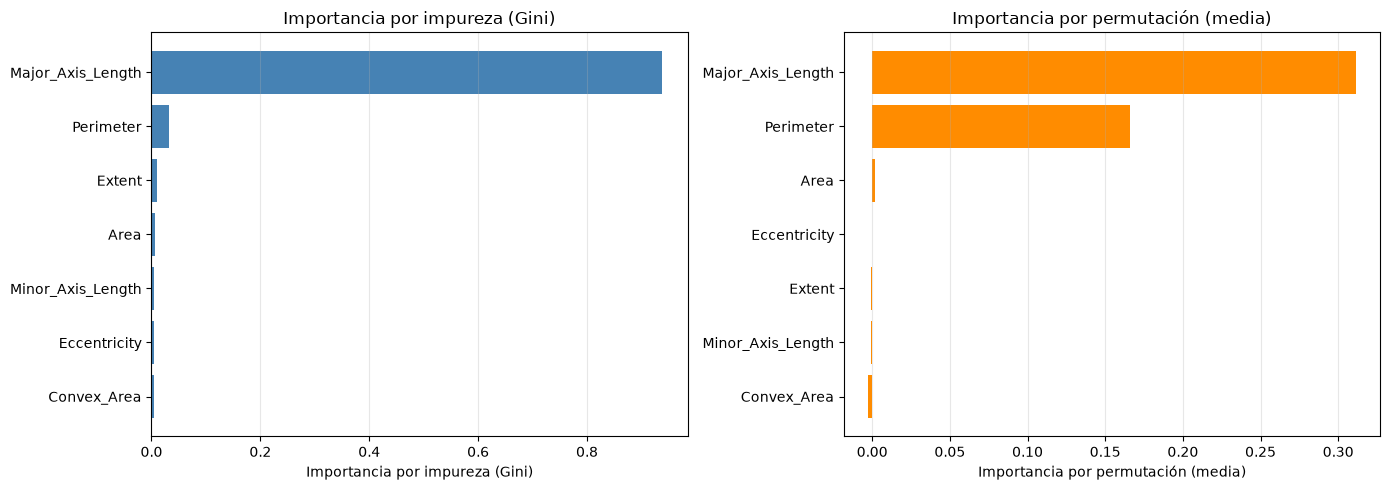

In [17]:
# ============================================================
# 4.3 Importancia de features del Random Forest
# ============================================================
importancias = pd.DataFrame({
    "Feature": feature_names,
    "Importancia por impureza (Gini)": rf_best.feature_importances_,
})

perm = permutation_importance(
    rf_best, X_test, y_test,
    n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1,
)
importancias["Importancia por permutación (media)"] = perm.importances_mean
importancias["Desv. est. permutación"] = perm.importances_std
importancias = importancias.sort_values(
    "Importancia por impureza (Gini)", ascending=False
)
display(importancias.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, columna, color in zip(
    axes,
    ["Importancia por impureza (Gini)", "Importancia por permutación (media)"],
    ["steelblue", "darkorange"],
):
    datos = importancias.sort_values(columna)
    ax.barh(datos["Feature"], datos[columna], color=color)
    ax.set_xlabel(columna)
    ax.set_title(columna)
    ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "04c_rf_importance.png", dpi=160, bbox_inches="tight")
plt.show()

**Lectura de la importancia.** `Major_Axis_Length` domina claramente: `[0.9377]` de la importancia por impureza y `[0.3112]` de caída media de exactitud al permutarla. `Perimeter` es la segunda (`[0.0315]` y `[0.1657]`). Las demás (`Extent`, `Area`, `Minor_Axis_Length`, `Eccentricity`, `Convex_Area`) quedan cerca de cero; algunas tienen importancia por permutación negativa (`[-0.0009]`, `[-0.0025]`), lo que significa que permutarlas no empeora el test e incluso puede mejorarlo por azar: son candidatas a eliminarse en un modelo más simple. La diferencia entre las dos medidas es instructiva: la impureza concentra casi todo en `Major_Axis_Length` porque el árbol la usa en muchos cortes, mientras que la permutación reparte algo más con `Perimeter`, que está correlacionado con el tamaño del grano. Para el informe, la importancia por permutación es la más defendible; la de impureza sirve como complemento.

### Comparación SVC vs. Random Forest

| Criterio | SVC (RBF) | Random Forest |
|---|---|---|
| Interpretabilidad | Baja: la frontera es una combinación de kernels; no hay reglas directas. Se puede aproximar con importancia por permutación, pero es un modelo de caja negra. | Alta: se puede descomponer en árboles, obtener importancia de features y explicar reglas (como el árbol de 3.2). |
| Tiempo de entrenamiento | `[0.037]` s para un ajuste en este problema (3048 × 7); el `GridSearchCV` tardó `[5.22]` s. Escala mal con el número de muestras (aprox. O(n²)–O(n³)) y con muchas features. | `[0.471]` s para un ajuste; el `GridSearchCV` tardó `[20.42]` s. Escala mejor y paraleliza bien; con más árboles el costo crece linealmente. |
| Sensibilidad a la escala | Alta: requiere estandarizar. Sin escalar, `Area` domina la distancia y el RBF puede funcionar mal. | Nula frente a transformaciones monótonas: los cortes son umbrales, así que no necesita escalar. |
| No linealidad | Muy flexible con kernel RBF; fronteras suaves y globales. | Muy flexible con cortes axis-aligned; fronteras escalonadas. En este dataset ambos llegan a ≈91 %, lo que sugiere una frontera relativamente simple. |
| Riesgo de sobreajuste | Controlado por `C` y `gamma`. `gamma` alto o `C` alto pueden sobreajustar; la CV ayuda a elegirlos. | Controlado por `max_depth`, `min_samples_leaf`, `max_features` y el número de árboles. Árboles muy profundos sobreajustan, pero el promedio reduce la varianza. En 3.3, `max_depth=5` fue mejor que `10` o `None`. |
| Número de hiperparámetros | Pocos: `C`, `gamma`, `kernel` (y `degree`, `coef0` para otros kernels). Es sensible a ellos. | Más: `n_estimators`, `max_depth`, `max_features`, `min_samples_split`, `min_samples_leaf`, `max_samples`, `class_weight`, etc. Es más tolerante a valores no óptimos. |
| Desbalance | `class_weight` disponible; en 4.4 mejora el recall de Cammeo. | `class_weight` y `balanced_subsample`; en 4.4 también mejora el recall de Cammeo. |
| Costo de predicción | Puede ser alto con muchos vectores de soporte; aquí es rápido. | Rápido y paralelizable; con 100 árboles es algo más costoso que un solo árbol. |

**Conclusión para este problema.** El SVC es el mejor por exactitud de prueba (`[0.9160]` vs. `[0.9121]`), pero la diferencia es menor que la variabilidad de la CV y no es concluyente. El Random Forest ofrece una ventaja clara en interpretabilidad y no requiere escalado, y su exactitud es prácticamente la misma. El árbol individual es el más fácil de explicar, pero es el que más riesgo tiene de sobreajuste si se permite crecer. Para un informe académico, una recomendación razonable es: **SVC si el objetivo es exprimir unas décimas de exactitud y el pipeline ya está estandarizado; Random Forest si se valora interpretabilidad, robustez y facilidad de uso; árbol individual solo como modelo explicativo o línea base**. Si se quiere simplificar, `Major_Axis_Length` y `Perimeter` concentran casi toda la señal, así que un modelo con esas dos features probablemente rendiría de forma similar.

## 4.4 `class_weight` y su efecto

`class_weight='balanced'` asigna a cada clase un peso inversamente proporcional a su frecuencia:

$$
w_c = \frac{n_{\text{muestras}}}{n_{\text{clases}} \cdot n_c}.
$$

Con el train de esta partición (`Cammeo=1304`, `Osmancik=1744`, total 3048), los pesos son `Cammeo ≈ [1.1687]` y `Osmancik ≈ [0.8739]`. Así, un error en Cammeo pesa más que un error en Osmancik. En el árbol y el bosque esto cambia el cálculo de impureza (Gini ponderado); en el SVC cambia el término de penalización de cada punto. El efecto esperado es **subir el recall de la clase minoritaria** a costa de precisión en esa clase y, a veces, de exactitud global.

Se entrenan los tres modelos con los mejores hiperparámetros encontrados y con `class_weight=None` vs. `class_weight='balanced'`. Se mantienen fijos los hiperparámetros para aislar el efecto del peso; en una búsqueda conjunta habría que volver a optimizarlos. Si tu `svc_best` ya venía entrenado con `class_weight='balanced'`, la fila `SVC` de 4.1 refleja ese peso; aquí se fuerza explícitamente `None` vs. `balanced` para comparar el cambio.

Pesos de class_weight='balanced': {'Cammeo': np.float64(1.1687), 'Osmancik': np.float64(0.8739)}


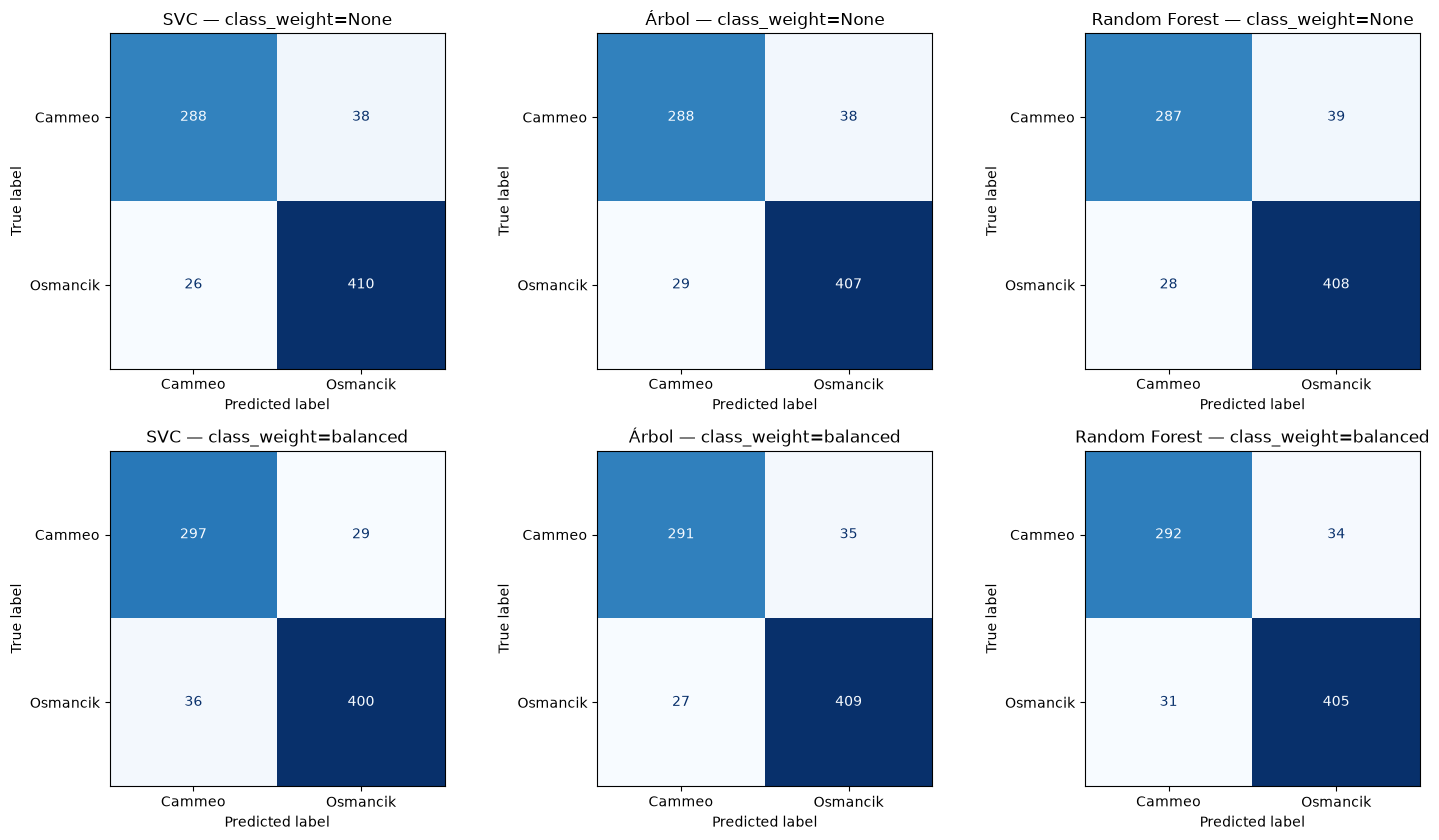

,Modelo,class_weight,Exactitud,Balanced accuracy,F1 macro,Precisión Cammeo,Recall Cammeo,Precisión Osmancik,Recall Osmancik
0,SVC,None,0.9160,0.9119,0.9138,0.9172,0.8834,0.9152,0.9404
1,SVC,balanced,0.9147,0.9142,0.9131,0.8919,0.9110,0.9324,0.9174
2,Árbol,None,0.9121,0.9085,0.9099,0.9085,0.8834,0.9146,0.9335
3,Árbol,balanced,0.9186,0.9154,0.9166,0.9151,0.8926,0.9212,0.9381
4,Random Forest,None,0.9121,0.9081,0.9098,0.9111,0.8804,0.9128,0.9358
5,Random Forest,balanced,0.9147,0.9123,0.9128,0.9040,0.8957,0.9226,0.9289


In [18]:
# ============================================================
# 4.4 Comparación con y sin class_weight='balanced'
# ============================================================
pesos = len(y_train) / (len(class_names) * np.bincount(y_train))
print("Pesos de class_weight='balanced':", dict(zip(class_names, np.round(pesos, 4))))

def ajustar_class_weight(modelo, cw):
    '''Clona el modelo y fija class_weight, también dentro de un Pipeline.'''
    m = clone(modelo)
    if isinstance(m, Pipeline):
        m.set_params(svc__class_weight=cw)
    else:
        m.set_params(class_weight=cw)
    return m.fit(X_train, y_train)

modelos_cw = {}
for nombre, modelo in modelos.items():
    for cw in [None, "balanced"]:
        modelos_cw[(nombre, cw)] = ajustar_class_weight(modelo, cw)

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for j, nombre in enumerate(modelos):
    for i, cw in enumerate([None, "balanced"]):
        ax = axes[i, j]
        y_pred = modelos_cw[(nombre, cw)].predict(X_test)
        ConfusionMatrixDisplay.from_predictions(
            y_test, y_pred, display_labels=class_names,
            cmap="Blues", colorbar=False, ax=ax,
        )
        etiqueta = "None" if cw is None else "balanced"
        ax.set_title(f"{nombre} — class_weight={etiqueta}")
fig.tight_layout()
fig.savefig(FIG_DIR / "04d_confusion_classweight.png", dpi=160, bbox_inches="tight")
plt.show()

filas = []
for (nombre, cw), modelo in modelos_cw.items():
    y_pred = modelo.predict(X_test)
    precision = precision_score(y_test, y_pred, average=None, labels=range(len(class_names)))
    recall = recall_score(y_test, y_pred, average=None, labels=range(len(class_names)))
    fila = {
        "Modelo": nombre,
        "class_weight": "None" if cw is None else "balanced",
        "Exactitud": accuracy_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
    }
    for i, c in enumerate(class_names):
        fila[f"Precisión {c}"] = precision[i]
        fila[f"Recall {c}"] = recall[i]
    filas.append(fila)

tabla_4d = pd.DataFrame(filas)
display(tabla_4d.round(4))

**Interpretación de los cambios.**
- **SVC:** la exactitud baja levemente de `[0.9160]` a `[0.9147]`, pero la balanced accuracy sube de `[0.9119]` a `[0.9142]` y el recall de Cammeo sube de `[0.8834]` a `[0.9110]` (+2.76 puntos). El costo se ve en la precisión de Cammeo, que baja de `[0.9172]` a `[0.8919]`: el modelo detecta más Cammeo, pero también genera más falsos positivos de Cammeo. El recall de Osmancik baja de `[0.9404]` a `[0.9174]` y el F1 macro baja levemente de `[0.9138]` a `[0.9131]`.
- **Árbol:** mejora en casi todo: exactitud `[0.9121] → [0.9186]`, balanced accuracy `[0.9085] → [0.9154]`, recall de Cammeo `[0.8834] → [0.8926]` y recall de Osmancik `[0.9335] → [0.9381]`. En este split, el peso balanceado cambió los cortes y encontró una partición mejor para ambas clases; no siempre ocurre así, pero es un resultado válido.
- **Random Forest:** exactitud `[0.9121] → [0.9147]`, balanced accuracy `[0.9081] → [0.9123]`, recall de Cammeo `[0.8804] → [0.8957]` (+1.53 puntos). El recall de Osmancik baja levemente (`[0.9358] → [0.9289]`) y la precisión de Cammeo baja de `[0.9111]` a `[0.9040]`; el patrón es el esperado: más sensibilidad a la minoría, algo menos de precisión.

**Conclusión de 4.4.** `class_weight='balanced'` es útil cuando **no detectar un Cammeo es más costoso que una falsa alarma**. En este dataset el efecto es moderado porque el desbalance es leve (57/43); con un desbalance más fuerte, el intercambio sería mucho más marcado. Si el objetivo es maximizar exactitud, el SVC sin pesos es ligeramente mejor; si el objetivo es tratar las clases por igual o priorizar la minoría, el SVC/árbol/RF con `class_weight='balanced'` son preferibles, y en árbol/RF incluso mejoran la exactitud en este test. Para el bosque, `class_weight='balanced_subsample'` es otra opción a probar, porque balancea cada muestra bootstrap y suele funcionar bien con desbalance.

# Conclusiones generales

1. **Pregunta 1:** el kernel cuadrático se puede escribir como un producto punto en un espacio de $\frac{(d+1)(d+2)}{2}$ componentes. Para $d=2$, $\varphi([2,-3]^\top)=[4,9,-6\sqrt2,6\sqrt2,-9\sqrt2,9]$ y $\varphi(\mathbf{x})^\top\varphi(\mathbf{z})=K(\mathbf{x},\mathbf{z})=1$ con $\mathbf{z}=[1,4]^\top$. Calcular $\varphi(\mathbf{x})^\top\varphi(\mathbf{z})$ cuesta $\mathcal{O}(d^2)$; calcular $K(\mathbf{x},\mathbf{z})$ cuesta $\mathcal{O}(d)$.
2. **Pregunta 2:** el dataset Rice cumple los requisitos (3810 ejemplos, 7 features, 2 clases). El SVC bidimensional con `Major_Axis_Length` y `Perimeter` alcanza ≈ `[0.93]` de validación; `gamma` controla la suavidad/localidad de la frontera y `C` el margen. El mejor pipeline `StandardScaler + SVC` usa `C=[10]`, `gamma=[0.01]`, con CV `[0.9324]` y prueba `[0.9160]`.
3. **Pregunta 3:** el árbol óptimo por CV tiene `max_depth=[4]` (`[0.9298]` de validación, `[0.9121]` de prueba); profundidades mayores sobreajustan. El árbol de profundidad 3 es interpretable: la raíz corta por `Major_Axis_Length` y separa un bloque grande de Osmancik; la rama de granos largos usa `Perimeter`, `Minor_Axis_Length` y de nuevo `Major_Axis_Length` para identificar Cammeo. El Random Forest óptimo es `[n_estimators=100, max_depth=5, max_features=None]` (`[0.9301]` de CV, `[0.9121]` de prueba).
4. **Pregunta 4:** SVC `[0.9160]`, árbol `[0.9121]`, Random Forest `[0.9121]` de exactitud de prueba. Las diferencias son pequeñas y menores que la variabilidad de la CV; no hay un ganador estadísticamente claro con este test. El SVC tiene la mejor exactitud puntual; el bosque, la mejor relación interpretabilidad/rendimiento; el árbol, la mejor explicabilidad. La exactitud es aceptable porque el desbalance es leve, pero oculta que el recall de Cammeo (`[0.880–0.883]`) es varios puntos menor que el de Osmancik (`[0.934–0.940]`). `class_weight='balanced'` sube el recall de Cammeo entre `[0.9]` y `[2.8]` puntos porcentuales según el modelo, con un efecto pequeño o incluso positivo en la exactitud global en esta partición.

> **Para tu informe:** reemplaza los valores entre corchetes por los que imprima tu ejecución si tu partición o tu preprocesamiento difieren. Las tablas y figuras se generan automáticamente en `figs/`.